# [8.4] ACDC and Circuit Metrics (solutions)

> **Colab: [exercises](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter8_automated_circuits/exercises/part4_acdc_circuit_metrics/8.4_ACDC_and_Circuit_Metrics_exercises.ipynb) |
> [solutions](https://colab.research.google.com/github/shinobiultra/ARENA_3.0_Extended/blob/main/chapter8_automated_circuits/exercises/part4_acdc_circuit_metrics/8.4_ACDC_and_Circuit_Metrics_solutions.ipynb)**

> **Prediction practice: [start the guided workbook](../../../mastery_hub/units/extension_predictions/exercises.ipynb#section-8-4) before viewing this lesson's results.**
> Record a forecast, confidence and reasoning, then compare controls and predict a changed case. These reference-rich lessons support guided practice; prior exposure is not scored as unseen mastery.

This section is part of the ARENA extension. The solutions notebook is saved with all of its outputs, so you can use it as a reference for what every cell should produce.

You can collapse each section so only the headers are visible, by clicking the arrow symbol on the left hand side of the markdown header cells.

<img src="https://raw.githubusercontent.com/info-arena/ARENA_img/main/misc/headers/header-13-2.png" width="350">

# Introduction

> **Fresh execution provenance (2026-10-16):** all 41 solution code cells completed in a fresh CUDA kernel on the RTX 5090 Laptop GPU. The published task, seed and threshold
> settings completed, including all five new semantic checks. Saved outputs and figures come from that run. The pre-repair historical references and the failed busy-GPU admission
> remain preserved separately. This is a reproduction on the existing evaluation cases, not an independent untouched TEST or learner acceptance. See
> `docs/mastery/evidence/pilot_fresh_execution_20261016/` in the checkout for the pinned inputs, partials and execution receipts.

In [1.2] you reverse-engineered the induction circuit of a two-layer attention-only transformer by hand. You looked at attention patterns, found a previous-token head in layer 0
(head 0.7), found induction heads in layer 1 (1.4 and 1.10), and showed with weight-based analysis that they're connected by **K-composition**: the induction heads' keys are built
from the previous-token head's output. That took you a few hours, and a lot of it relied on knowing roughly what you were looking for.

Here's a different way to get there. Write the model down as a graph, where every attention head reads from the heads before it through a separate edge into its query, key and value. Then hand a program three things: the model, a dataset on which the behaviour happens, and a number $\tau$. The program deletes edges one at a time, keeping each deletion if it changes the model's output by less than $\tau$, and hands back whatever survives. That's **ACDC**, *Automatic Circuit DisCovery* ([Conmy et al., 2023](https://arxiv.org/abs/2304.14997)). On the model from [1.2], with no hint about what to look for, it returns a 16-edge graph that contains every piece of the induction circuit you found, plus one piece you didn't.

The harder question is the one in this section's title. **When an algorithm hands you a circuit, how do you know it's the circuit?** A subgraph can reproduce the model's output for
the wrong reasons, can leave out components that matter, or can carry passengers that don't. So the second half of this section is about evaluating circuits, with three metrics
from the literature and the controls that make them meaningful:

- **Faithfulness**: how much of the model's behaviour does the circuit recover on held-out data, compared with *random circuits of the same size*?
- **Completeness**: does the circuit contain everything that matters, or does the rest of the model also carry the behaviour (Wang et al., 2022)?
- **Minimality**: does every edge in the circuit earn its place?

Finally we'll run your ACDC implementation, unchanged, on GPT-2 Small's greater-than task, and compare what it finds with the circuit [Hanna et al. (2023)](https://arxiv.org/abs/2305.00586) identified by hand.

This section assumes [1.2] (induction heads, K-composition, the attention-only model) and [8.1] (activation patching). Part 4️⃣ reuses the GPT-2 edge graph you built in [8.2].

## Content & Learning Objectives

### 1️⃣ The Model as a Graph

You'll write the two-layer model from [1.2] as a computational graph of 25 senders and 73 receivers, implement a forward pass in which any set of edges can be cut (replaced by
their values on a corrupted input), and measure the effect of cutting each edge on its own.

> ##### Learning Objectives
>
> - Understand the edge-level view of a transformer: senders, receivers, and why queries, keys and values are separate receivers
> - Implement a forward pass with edge interventions, including recomputation of everything downstream
> - Understand KL divergence as a "faithful to the whole model" metric, and why it needs a separate task metric alongside it
> - See what single-edge interventions can and can't tell you

### 2️⃣ ACDC

You'll implement ACDC, run it on induction, and compare the circuit it finds with the one from [1.2]. Then you'll sweep its threshold and compare it with a one-shot method that
doesn't recompute.

> ##### Learning Objectives
>
> - Implement ACDC: reverse-topological iteration, greedy edge removal against a threshold, and dropping nodes that leave the circuit
> - Recover the induction circuit automatically, and investigate the component it adds
> - Understand what the threshold controls, and why small per-edge thresholds can add up to a large total error

### 3️⃣ Is It the Right Circuit?

You'll evaluate the circuits ACDC finds with faithfulness (against same-size random circuits), completeness and minimality, and with an ROC curve against the circuit from [1.2].

> ##### Learning Objectives
>
> - Compute normalised faithfulness on held-out prompts, and compare against same-size random circuits
> - Implement the completeness test of Wang et al. and read its scatter plot
> - Measure per-edge minimality and see how it changes with the threshold
> - Understand what an ROC curve against a reference circuit measures, and how much it depends on the reference

### 4️⃣ ACDC on GPT-2: Greater-Than

You'll run your ACDC implementation on GPT-2 Small's greater-than task, using the edge graph and patched forward pass from [8.2], and compare the result against the circuit found
by Hanna et al.

> ##### Learning Objectives
>
> - Apply ACDC to a real 12-layer model, and understand where its cost comes from
> - Compare an automatically discovered circuit with a hand-found one, component by component
> - Check faithfulness on held-out prompts against same-size random circuits

### ☆ Bonus

Edge order and threshold sensitivity, ACDC with a task metric instead of KL, head-level graphs, and further reading.

## Setup code

In [1]:
import os
import sys
#
IN_COLAB = "google.colab" in sys.modules
#
if IN_COLAB:
    # Install dependencies, and download this chapter's exercise files from the ARENA extension repo
    %pip install transformer_lens==2.16.1 jaxtyping
    repo, branch, chapter = "ARENA_3.0_Extended", "main", "chapter8_automated_circuits"
    if not os.path.exists(f"/content/{chapter}"):
        !wget -P /content https://github.com/shinobiultra/{repo}/archive/refs/heads/{branch}.zip
        !unzip -q /content/{branch}.zip '{repo}-{branch}/{chapter}/exercises/*' -d /content
        !mv /content/{repo}-{branch}/{chapter} /content/{chapter}
        !rm -r /content/{branch}.zip /content/{repo}-{branch}
    os.chdir(f"/content/{chapter}/exercises")

In [2]:
import sys
import time
from collections.abc import Callable
from pathlib import Path

import einops
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch as t
from IPython.display import display
from jaxtyping import Bool, Float, Int
from torch import Tensor
from tqdm.auto import tqdm
from transformer_lens import HookedTransformer

device = t.device("mps" if t.backends.mps.is_available() else "cuda" if t.cuda.is_available() else "cpu")

# Make sure exercises are in the path
chapter = "chapter8_automated_circuits"
section = "part4_acdc_circuit_metrics"
root_dir = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / chapter).exists())
exercises_dir = root_dir / chapter / "exercises"
section_dir = exercises_dir / section
if str(exercises_dir) not in sys.path:
    sys.path.append(str(exercises_dir))

import part4_acdc_circuit_metrics.tests as tests
import part4_acdc_circuit_metrics.utils as utils

# Part 4️⃣ reuses the GPT-2 edge graph and greater-than task from [8.2]
import part2_attribution_patching_eap.solutions as gpt2_graph

MAIN = __name__ == "__main__"

W1016 12:39:07.478000 1048917 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1016 12:39:07.499000 1048917 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


# 1️⃣ The Model as a Graph

> ##### Learning Objectives
>
> - Understand the edge-level view of a transformer: senders, receivers, and why queries, keys and values are separate receivers
> - Implement a forward pass with edge interventions, including recomputation of everything downstream
> - Understand KL divergence as a "faithful to the whole model" metric, and why it needs a separate task metric alongside it
> - See what single-edge interventions can and can't tell you

## The model and the task

We'll use the two-layer attention-only model from [1.2]: 12 heads per layer, $d_{model} = 768$, no MLPs and no layernorm. It uses *shortformer* positional embeddings, which means
the positional embedding is never written into the residual stream; instead it's added directly to the inputs of every query and key. Keep that in mind, because it means that
position information doesn't flow along any of the edges we're about to define.

In [3]:
model = utils.load_attn_only_2l(device)
print(f"{model.cfg.n_layers} layers, {model.cfg.n_heads} heads per layer, positional embeddings: {model.cfg.positional_embedding_type}")

Moving model to device:  cuda
2 layers, 12 heads per layer, positional embeddings: shortformer


The task is the one from [1.2]: predict the second half of a repeated sequence of random tokens. A clean prompt is

$$
[\text{BOS}, r_1, r_2, \ldots, r_n, r_1, r_2, \ldots, r_n]
$$

for random tokens $r_i$. On the first half the model can only guess, but on the second half an induction circuit can look back at what followed the current token last time and
predict it again.

For ACDC we also need a **corrupted** prompt, which defines what "cutting an edge" means: a cut edge carries the value its sender would have had on the corrupted prompt. Our
corrupted prompts are $[\text{BOS}, s_1, \ldots, s_{2n}]$ with all-new random tokens and no repetition, so every sender's corrupted output carries no information about the clean
sequence, and there's nothing to induct on. Clean and corrupted prompts have the same length, which matters because the positional embeddings (which aren't part of the graph) are
then identical in both.

We'll measure everything at the positions where induction can work: positions $n+1$ to $2n-1$, where the model has seen the current token before and should predict the token that
followed it. We use 64 prompts with $n = 20$ for discovery, and a separate 64 prompts for evaluation.

In [4]:
HALF_LEN = 20
INDUCTION_POS = slice(HALF_LEN + 1, 2 * HALF_LEN)  # positions whose next token is predictable by induction

clean, corrupt = utils.make_induction_data(model, n_prompts=64, half_len=HALF_LEN, seed=0)
heldout_clean, heldout_corrupt = utils.make_induction_data(model, n_prompts=64, half_len=HALF_LEN, seed=1)

print("clean:  ", [model.to_string(tok) for tok in clean[0, :8]], "...", [model.to_string(tok) for tok in clean[0, HALF_LEN + 1 : HALF_LEN + 5]])
print("corrupt:", [model.to_string(tok) for tok in corrupt[0, :8]], "...", [model.to_string(tok) for tok in corrupt[0, HALF_LEN + 1 : HALF_LEN + 5]])
print(f"shapes: {tuple(clean.shape)}, induction positions {INDUCTION_POS.start}..{INDUCTION_POS.stop - 1}")

clean:   ['<|endoftext|>', 'Th', ' sets', 'teen', 'rial', 'astern', ' decrease', 'rate'] ... ['Th', ' sets', 'teen', 'rial']
corrupt: ['<|endoftext|>', ' sequ', ' absolutely', ' testing', ' \\[[@', ' physical', ' Italy', 'plant'] ... ['under', ' records', 'ification', ' storage']
shapes: (64, 41), induction positions 21..39


<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">clean:   ['&lt;|endoftext|&gt;', 'Th', ' sets', 'teen', 'rial', 'astern', ' decrease', 'rate'] ... ['Th', ' sets', 'teen', 'rial']
corrupt: ['&lt;|endoftext|&gt;', ' sequ', ' absolutely', ' testing', ' \\[[@', ' physical', ' Italy', 'plant'] ... ['under', ' records', 'ification', ' storage']
shapes: (64, 41), induction positions 21..39</pre>

</details>

## Senders, receivers and edges

A transformer's residual stream is a sum. Every component reads the sum of everything written before it, and adds its own output. So we can rewrite the model as a graph:

- **Senders** are things that write to the residual stream: the token embedding, and the output of each attention head (its $z$ times $W_O$, *without* the shared bias $b_O$). That's $1 + 2 \times 12 = 25$ senders.
- **Receivers** are things that read from the residual stream. Each head reads it three times, once for its **query**, once for its **key** and once for its **value**, and we treat these as three separate receivers. The unembedding reads it once more to produce the **logits**. That's $2 \times 12 \times 3 + 1 = 73$ receivers.
- There's an **edge** from sender $u$ to receiver $v$ whenever $u$ writes before $v$ reads: the embedding feeds every receiver, layer-0 heads feed layer-1 queries, keys and values and the logits, and layer-1 heads feed the logits.

Why split each head into three receivers? Because in [1.2] the interesting structure was exactly here: an induction head is built by **K-composition**, where its *key* reads the
previous-token head's output, while its *query* and *value* read the token embedding. A graph with one receiver per head couldn't express that distinction.

The input to receiver $v$ is

$$
x_v = \sum_{u \to v} \text{out}_u + \text{biases},
$$

and that sum is what makes edge-level interventions possible: to cut the edge $u \to v$, replace that one term with $\text{out}_u$ from the corrupted run, and leave every other
term alone. The biases ($b_O$ of each earlier layer) are the same on every input, so we just add them in.

We'll index senders and receivers like this:

In [5]:
N_LAYERS, N_HEADS = 2, 12
SENDER_NAMES = ["embed"] + [f"{layer}.{head}" for layer in range(N_LAYERS) for head in range(N_HEADS)]
RECEIVER_NAMES = [f"{layer}.{head}<{c}>" for layer in range(N_LAYERS) for c in "qkv" for head in range(N_HEADS)] + ["logits"]
N_SENDERS, N_RECEIVERS = len(SENDER_NAMES), len(RECEIVER_NAMES)
LOGITS = N_RECEIVERS - 1


def head_sender(layer: int, head: int) -> int:
    return 1 + layer * N_HEADS + head


def head_receiver(layer: int, c: str, head: int) -> int:
    """Index of the receiver for the query ("q"), key ("k") or value ("v") input of a head."""
    return layer * 3 * N_HEADS + "qkv".index(c) * N_HEADS + head


assert SENDER_NAMES[head_sender(0, 7)] == "0.7" and RECEIVER_NAMES[head_receiver(1, "k", 4)] == "1.4<k>"
print(f"{N_SENDERS} senders, {N_RECEIVERS} receivers")

25 senders, 73 receivers


### Exercise - build the edge mask

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5 minutes on this exercise.
> ```

Return a boolean tensor of shape `(N_SENDERS, N_RECEIVERS)` which is `True` exactly where there's an edge: the embedding to every receiver, every layer-0 head to every layer-1
query, key and value and to the logits, and every layer-1 head to the logits. You should get 529 edges.

In [6]:
def build_edge_mask() -> Bool[Tensor, "sender receiver"]:
    mask = t.zeros(N_SENDERS, N_RECEIVERS, dtype=t.bool)
    mask[0, :] = True
    for head in range(N_HEADS):
        mask[head_sender(0, head), head_receiver(1, "q", 0) :] = True  # all layer-1 receivers, and the logits
        mask[head_sender(1, head), LOGITS] = True
    return mask


tests.test_build_edge_mask(build_edge_mask)

EDGE_MASK = build_edge_mask()

All tests in `test_build_edge_mask` passed!


### Exercise - sender outputs

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵⚪⚪⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement `sender_outputs`, which runs the model on `tokens` and returns every sender's output, stacked into a tensor of shape `(batch, seq, N_SENDERS, d_model)`. Sender 0 is the
token embedding (`hook_embed`). The heads' outputs, *without* the bias $b_O$, are cached at `blocks.{layer}.attn.hook_result` with shape `(batch, seq, n_heads, d_model)` (this hook
exists because the model was created with `use_attn_result=True`).

We'll call this on the corrupted prompts, to get the values that cut edges carry.

In [7]:
@t.no_grad()
def sender_outputs(model: HookedTransformer, tokens: Int[Tensor, "batch seq"]) -> Float[Tensor, "batch seq sender d_model"]:
    names = ["hook_embed"] + [f"blocks.{layer}.attn.hook_result" for layer in range(N_LAYERS)]
    _, cache = model.run_with_cache(tokens, names_filter=lambda name: name in names)
    return t.cat([cache["hook_embed"][:, :, None]] + [cache[f"blocks.{layer}.attn.hook_result"] for layer in range(N_LAYERS)], dim=2)


tests.test_sender_outputs(sender_outputs, model, clean[:4])

All tests in `test_sender_outputs` passed!


The test checks the identity that makes the whole graph view work: the senders' outputs, plus the output biases, add up exactly to the final residual stream.

## Running the model as a graph

Now the central piece. Given a set of edges `in_circuit` (a boolean `(sender, receiver)` mask), we want to run the model on the clean prompt where:

- every edge **in** the circuit carries its sender's **current** output in this run, and
- every valid edge **not** in the circuit carries its sender's output on the **corrupted** prompt.

"Current" matters. Suppose we cut the edge `embed -> 0.7<v>`. Then head 0.7's value input is corrupted, so its output in this run is different from its clean output, and every
layer-1 receiver that reads 0.7 through an edge in the circuit should see this *changed* output. This is what makes edge interventions more than a lookup table: effects propagate
downstream through the edges you keep.

For the two-layer model we can write the whole forward pass out by hand, which is cleaner than hooking into TransformerLens. For each layer:

1. Build the input of every receiver in the layer, as a tensor of shape `(batch, seq, n_heads, d_model)` for each of q, k and v:
   $$x_v = \sum_{u\,:\,(u, v) \in \text{circuit}} \text{out}^{\text{current}}_u + \sum_{u\,:\,(u, v) \in \text{edges} \setminus \text{circuit}} \text{out}^{\text{corrupt}}_u +
\sum_{\ell' < \ell} b_O^{(\ell')}$$
   `einops.einsum` with the masks (as floats) does each sum in one call.
2. Add the positional embedding `model.W_pos[:seq]` to the query and key inputs (not the value input).
3. Compute queries, keys and values with `model.W_Q[layer]`, `model.b_Q[layer]` etc. (`W_Q[layer]` has shape `(n_heads, d_model, d_head)`), the attention scores scaled by $1/\sqrt{d_{head}}$, the causal mask, the softmax, $z$, and each head's output $z W_O$.
4. Store the heads' outputs as the *current* outputs of their senders, for the next layer to read.

Finally, the logits receiver gets the same treatment (with both layers' $b_O$), followed by `@ model.W_U + model.b_U`.

One thing to be careful about: only sum over **valid** edges. A layer-1 head is not an edge into a layer-0 query, so it must not contribute to it in either sum, whatever
`in_circuit` says about that entry.

### Exercise - implement `run_graph`

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 25-35 minutes on this exercise.
> ```

Implement `run_graph` as described above, returning logits of shape `(batch, seq, d_vocab)`. `corrupt_out` comes from `sender_outputs(model, corrupt_tokens)`. Don't decorate it
with `no_grad`: in the bonus we'll want to differentiate through it.

The tests check three things: with every edge in the circuit you get the model's logits; with no edges you get the model's logits on the corrupted prompts; and cutting a single
edge agrees with patching that one input using TransformerLens hooks.

In [8]:
def run_graph(
    model: HookedTransformer,
    tokens: Int[Tensor, "batch seq"],
    corrupt_out: Float[Tensor, "batch seq sender d_model"],
    in_circuit: Tensor,
) -> Float[Tensor, "batch seq d_vocab"]:
    """
    Runs the two-layer model on `tokens`, where each valid edge in `in_circuit` carries its sender's current output
    and each valid edge outside it carries the sender's corrupted output.
    """
    batch, seq = tokens.shape
    valid = EDGE_MASK.to(tokens.device).float()
    keep = in_circuit.to(tokens.device).float() * valid
    cut = valid - keep

    current = t.zeros_like(corrupt_out)
    current[:, :, 0] = model.W_E[tokens]
    pos = model.W_pos[:seq][:, None]  # (seq, 1, d_model), broadcasts over heads
    causal = t.triu(t.ones(seq, seq, dtype=t.bool, device=tokens.device), diagonal=1)
    bias = t.zeros(model.cfg.d_model, device=tokens.device)

    for layer in range(N_LAYERS):

        def receiver_input(c: str) -> Tensor:
            cols = slice(head_receiver(layer, c, 0), head_receiver(layer, c, 0) + N_HEADS)
            return (
                einops.einsum(current, keep[:, cols], "b p s d, s h -> b p h d")
                + einops.einsum(corrupt_out, cut[:, cols], "b p s d, s h -> b p h d")
                + bias
            )

        q = einops.einsum(receiver_input("q") + pos, model.W_Q[layer], "b p h d, h d e -> b p h e") + model.b_Q[layer]
        k = einops.einsum(receiver_input("k") + pos, model.W_K[layer], "b p h d, h d e -> b p h e") + model.b_K[layer]
        v = einops.einsum(receiver_input("v"), model.W_V[layer], "b p h d, h d e -> b p h e") + model.b_V[layer]
        scores = einops.einsum(q, k, "b q h e, b k h e -> b h q k") / model.cfg.d_head**0.5
        pattern = scores.masked_fill(causal, float("-inf")).softmax(dim=-1)
        z = einops.einsum(pattern, v, "b h q k, b k h e -> b q h e")
        start = head_sender(layer, 0)
        current[:, :, start : start + N_HEADS] = einops.einsum(z, model.W_O[layer], "b p h e, h e d -> b p h d")
        bias = bias + model.b_O[layer]

    final = (
        einops.einsum(current, keep[:, LOGITS], "b p s d, s -> b p d")
        + einops.einsum(corrupt_out, cut[:, LOGITS], "b p s d, s -> b p d")
        + bias
    )
    return final @ model.W_U + model.b_U


tests.test_run_graph(run_graph, sender_outputs, EDGE_MASK, model, clean, corrupt)

All tests in `test_run_graph` passed!


<details>
<summary>Hint - structure</summary>

Keep a tensor `current` of shape `(batch, seq, N_SENDERS, d_model)` holding the current outputs of the senders computed so far (start with the embedding in slot 0). For each layer,
build the three receiver inputs with two einsums each, one over `current` with the kept-edge mask and one over `corrupt_out` with the cut-edge mask, where `keep = in_circuit &
EDGE_MASK` and `cut = EDGE_MASK & ~in_circuit` (as floats).
</details>

<details>
<summary>Help - the "no edges" test passes, but the "every edge" test fails.</summary>

The "no edges" test is weaker than it looks. With no edges in the circuit, the logits receiver only sees corrupted sender outputs, so its input is the corrupted residual stream
*whatever happened inside the model*. A bug in your layer computations can't show up there. The "every edge" test is the one that checks your attention.

The most common bug is summing over *all* senders rather than only valid edges, for example using `1 - in_circuit` as the cut mask. That adds the corrupted outputs of later heads
(which aren't edges at all) into earlier receivers. Other things to check: the positional embedding goes into queries and keys only; the attention scale is $1/\sqrt{d_{head}}$; and
each layer's inputs include the $b_O$ of the layers *before* it.
</details>

## Metrics

ACDC needs a number that says how far a circuit's behaviour is from the full model's. Conmy et al. use the **KL divergence** from the full model's next-token distribution to the
circuit's, averaged over the positions we care about:

$$
D(C) = \mathbb{E}_{\text{prompt},\,\text{pos}} \left[ \text{KL}\big(p_{M}(\cdot) \,\|\, p_{C}(\cdot)\big) \right]
$$

KL is zero only when the circuit reproduces the model's whole distribution, not just its top answer, which makes it a demanding target that doesn't need a task-specific definition.
But it's not the quantity we actually care about. For evaluation we'll also use a **task metric**: the average log probability of the correct next token at the induction positions.
Using two different metrics is a good habit: a circuit found by minimising one metric should be checked with another.

### Exercise - KL divergence

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5 minutes on this exercise.
> ```

Implement `kl_divergence`, which takes the circuit's logits and the full model's log probabilities (both for the positions we care about, with shape `(batch, pos, d_vocab)`) and
returns the KL divergence from the full model to the circuit, summed over the vocabulary and averaged over batch and positions, as a scalar tensor.

In [9]:
def kl_divergence(
    circuit_logits: Float[Tensor, "batch pos d_vocab"], full_logprobs: Float[Tensor, "batch pos d_vocab"]
) -> Float[Tensor, ""]:
    circuit_logprobs = circuit_logits.log_softmax(dim=-1)
    return (full_logprobs.exp() * (full_logprobs - circuit_logprobs)).sum(dim=-1).mean()


tests.test_kl_divergence(kl_divergence)

All tests in `test_kl_divergence` passed!


The task metric is a one-liner, so here it is:

In [10]:
def induction_logprob(logits: Float[Tensor, "batch seq d_vocab"], tokens: Int[Tensor, "batch seq"]) -> float:
    """Mean log probability of the correct next token at the induction positions."""
    logprobs = logits[:, INDUCTION_POS].log_softmax(dim=-1)
    targets = tokens[:, INDUCTION_POS.start + 1 : INDUCTION_POS.stop + 1]
    return logprobs.gather(-1, targets[..., None]).mean().item()

Now we can wrap everything into two closures that take a circuit and return a number. We'll pass these to ACDC and to the evaluation functions, which means those functions never
need to know anything about the model.

In [11]:
corrupt_out = sender_outputs(model, corrupt)
heldout_corrupt_out = sender_outputs(model, heldout_corrupt)
with t.no_grad():
    full_logprobs = model(clean)[:, INDUCTION_POS].log_softmax(dim=-1)


@t.inference_mode()
def circuit_kl(circuit: Tensor) -> float:
    """KL divergence of the circuit from the full model, on the discovery prompts."""
    return kl_divergence(run_graph(model, clean, corrupt_out, circuit)[:, INDUCTION_POS], full_logprobs).item()


@t.inference_mode()
def circuit_logprob(circuit: Tensor) -> float:
    """Induction log probability of the circuit, on the held-out prompts."""
    return induction_logprob(run_graph(model, heldout_clean, heldout_corrupt_out, circuit), heldout_clean)


EMPTY = t.zeros_like(EDGE_MASK)
with t.inference_mode():
    print(f"Full model:    KL = {abs(circuit_kl(EDGE_MASK)):.3f}, induction log prob = {circuit_logprob(EDGE_MASK):.2f}")
    print(f"Empty circuit: KL = {circuit_kl(EMPTY):.3f}, induction log prob = {circuit_logprob(EMPTY):.2f}")
    lp_first = model(heldout_clean)[:, 1:HALF_LEN].log_softmax(-1).gather(-1, heldout_clean[:, 2 : HALF_LEN + 1, None]).mean().item()
    print(f"(For comparison, the full model's log prob on the unpredictable first half: {lp_first:.2f})")

Full model:    KL = 0.000, induction log prob = -3.23
Empty circuit: KL = 6.211, induction log prob = -13.43
(For comparison, the full model's log prob on the unpredictable first half: -13.51)


<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">Full model:    KL = 0.000, induction log prob = -3.23
Empty circuit: KL = 6.211, induction log prob = -13.43
(For comparison, the full model's log prob on the unpredictable first half: -13.51)</pre>

</details>

The full model puts an average log probability of −3.23 on the correct token at the induction positions (about a 4% chance, against 1 in 50,000 for a uniform guess), and the empty
circuit, which sees only corrupted values, is down at −13.43: no better than the full model does on the first half, where the tokens are unpredictable (−13.51). So everything
between −13.4 and −3.2 is induction, and that's the range faithfulness will measure. The empty circuit's KL of 6.2 nats is the other end of ACDC's scale.

## Cutting one edge at a time

Before ACDC, let's try the simplest possible approach: cut each edge on its own, with everything else intact, and measure the KL divergence. That's 529 forward passes, which takes
a few seconds for this model. This is the edge-level version of the activation patching sweeps from [8.1].

### Exercise - single-edge effects

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement `single_edge_effects`, which returns a `(sender, receiver)` tensor whose entry for each valid edge is `metric_fn` of the full graph with only that edge cut. Leave invalid
entries at zero.

In [12]:
def single_edge_effects(metric_fn: Callable[[Tensor], float], edge_mask: Tensor) -> Float[Tensor, "sender receiver"]:
    effects = t.zeros(edge_mask.shape)
    for u, v in tqdm(edge_mask.nonzero().tolist(), desc="single edges"):
        circuit = edge_mask.clone()
        circuit[u, v] = False
        effects[u, v] = metric_fn(circuit)
    return effects

In [13]:
tests.test_single_edge_effects(single_edge_effects)

single edges:   0%|          | 0/3 [00:00<?, ?it/s]

All tests in `test_single_edge_effects` passed!


single edges:   0%|          | 0/529 [00:00<?, ?it/s]

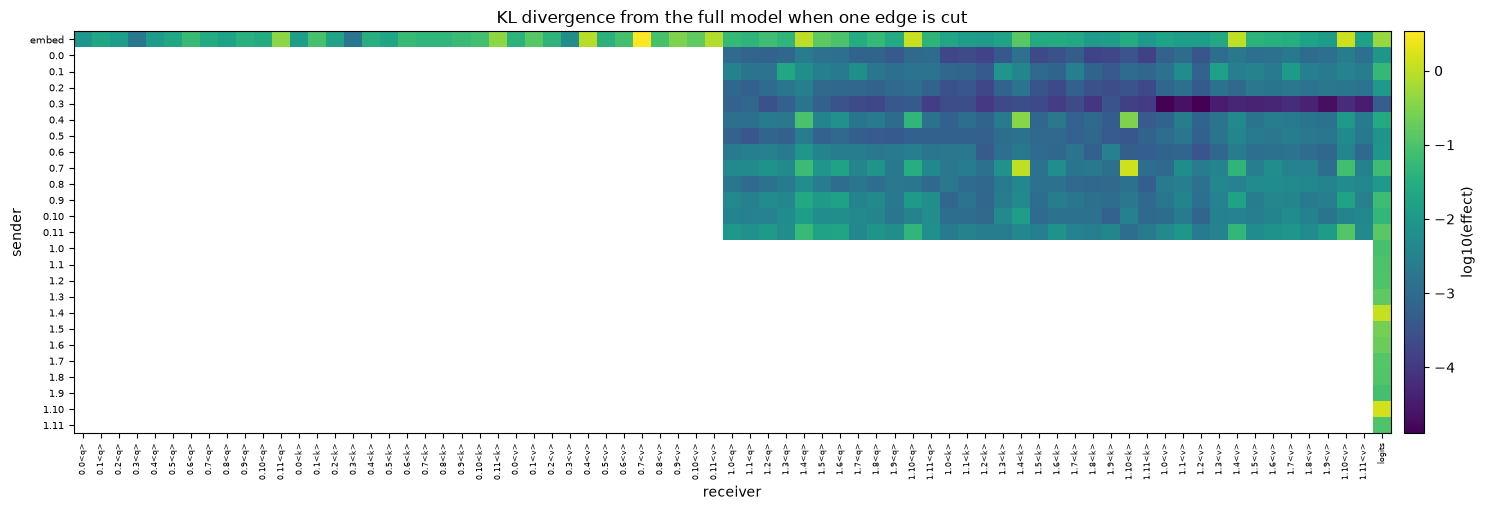

Edges with the largest single-edge effect:
   embed -> 0.7<v>   KL = 3.387
    1.10 -> logits   KL = 1.457
     0.7 -> 1.10<k>  KL = 1.344
   embed -> 1.10<v>  KL = 1.301
   embed -> 1.10<q>  KL = 1.194
     1.4 -> logits   KL = 1.144
     0.7 -> 1.4<k>   KL = 1.044
   embed -> 1.4<v>   KL = 1.009
   embed -> 1.4<q>   KL = 0.994
   embed -> 0.4<v>   KL = 0.894
   embed -> 0.11<v>  KL = 0.796
   embed -> logits   KL = 0.484
Edges with KL < 0.01: 409 of 529


In [14]:
single_kl = single_edge_effects(circuit_kl, EDGE_MASK)
utils.plot_edge_heatmap(single_kl, EDGE_MASK, SENDER_NAMES, RECEIVER_NAMES, "KL divergence from the full model when one edge is cut")

top = single_kl.flatten().topk(12)
print("Edges with the largest single-edge effect:")
for value, idx in zip(top.values.tolist(), top.indices.tolist()):
    u, v = divmod(idx, N_RECEIVERS)
    print(f"  {SENDER_NAMES[u]:>6} -> {RECEIVER_NAMES[v]:<8} KL = {value:.3f}")
print(f"Edges with KL < 0.01: {int(((single_kl < 0.01) & EDGE_MASK).sum())} of {int(EDGE_MASK.sum())}")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">Edges with the largest single-edge effect:
   embed -&gt; 0.7&lt;v&gt;   KL = 3.387
    1.10 -&gt; logits   KL = 1.457
     0.7 -&gt; 1.10&lt;k&gt;  KL = 1.344
   embed -&gt; 1.10&lt;v&gt;  KL = 1.301
   embed -&gt; 1.10&lt;q&gt;  KL = 1.194
     1.4 -&gt; logits   KL = 1.144
     0.7 -&gt; 1.4&lt;k&gt;   KL = 1.044
   embed -&gt; 1.4&lt;v&gt;   KL = 1.009
   embed -&gt; 1.4&lt;q&gt;   KL = 0.994
   embed -&gt; 0.4&lt;v&gt;   KL = 0.894
   embed -&gt; 0.11&lt;v&gt;  KL = 0.796
   embed -&gt; logits   KL = 0.484
Edges with KL &lt; 0.01: 409 of 529</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

The heatmap is mostly dark: 409 of the 529 edges change the KL by less than 0.01 when cut on their own. The bright cells are exactly the edges of the induction circuit from [1.2]:

- `embed -> 0.7<v>` (KL 3.39) is by far the most important single edge. That's the previous-token head reading the *token* it will move one position forward. (Its query and key don't matter, because 0.7 finds the previous position using the positional embeddings, which aren't part of the graph.)
- `0.7 -> 1.4<k>` and `0.7 -> 1.10<k>` are K-composition: the induction heads' keys carry "the token before me was X".
- `embed -> 1.4<q>`, `embed -> 1.10<q>` (the current token, which the query looks for) and `embed -> 1.4<v>`, `embed -> 1.10<v>` (the token that gets copied) are the induction heads' other inputs.
- `1.4 -> logits` and `1.10 -> logits` are where the prediction is written out, and `embed -> logits` is the direct path, which carries the bigram statistics.

Two edges in the top 12 aren't on that list: `embed -> 0.4<v>` and `embed -> 0.11<v>`. Keep an eye on them.

What this picture can't tell you is which of these edges are *needed together*. Every number here was measured with all the other 528 edges intact, so an edge whose job is
duplicated elsewhere will look unimportant, and an edge can look important only because of what it feeds.
</details>

## Summary of 1️⃣

- A transformer's residual stream is a sum of sender outputs, so the model can be written as a graph whose edges can be cut individually: replace one term of a receiver's input with its corrupted value.
- Treating each head's query, key and value as separate receivers lets the graph express Q-, K- and V-composition.
- Cutting an edge changes everything downstream of it. A correct edge-intervention forward pass recomputes the senders after the cut, and only sums over valid edges.
- Cutting single edges already highlights the induction circuit, but it measures each edge with every *other* edge intact, which is not the same as asking which edges a circuit needs.

# 2️⃣ ACDC

> ##### Learning Objectives
>
> - Implement ACDC: reverse-topological iteration, greedy edge removal against a threshold, and dropping nodes that leave the circuit
> - Recover the induction circuit automatically, and investigate the component it adds
> - Understand what the threshold controls, and why small per-edge thresholds can add up to a large total error

## The algorithm

Single-edge effects ask "what happens if I cut this edge, and nothing else?". A circuit is a different object: a *set* of edges that, together, does the job. The two can disagree
badly. Two redundant edges each look unimportant on their own (cutting either one leaves the other to do the work), but cutting both is a disaster. And an edge can look important
only because of what it feeds into, which you'd have cut anyway.

ACDC builds a circuit by **removing** edges one at a time, always measuring against the *current* circuit rather than the full model:

```
circuit = all edges
D = metric(circuit)
for each receiver v, from the output backwards:
    if v belongs to a node with no outgoing edges left in the circuit:
        remove every edge into v; continue      # the node isn't in the circuit, so its inputs don't matter
    for each sender u with an edge u -> v, latest sender first:
        D_new = metric(circuit without u -> v)
        if D_new - D < τ:                      # removing it barely matters
            remove u -> v; D = D_new
return circuit
```

Three details are doing a lot of work:

- **Reverse topological order.** Receivers are processed from the logits backwards. By the time we reach a head's inputs, we've already decided which of its *outputs* are in the circuit. If none are, the head has left the circuit, and we can drop its inputs without testing them. This is where most of ACDC's speed-up comes from on a big model.
- **Recomputation.** Every decision is made with the circuit as it currently is. If an edge's job is also done by another edge, the first one tested is removed, and the second then looks essential.
- **A threshold on each step, not on the total.** $\tau$ bounds the damage of each removal, not the final KL. Many small removals can add up.

The order in which we visit receivers and senders is a choice. We'll use the one from the ACDC code: receivers from the logits backwards, and within each receiver, senders from
latest to earliest.

In [15]:
# Receivers from the output backwards: logits, then layer-1 heads, then layer-0 heads (q, k, v of each head together)
RECEIVER_ORDER = [LOGITS] + [head_receiver(layer, c, head) for layer in reversed(range(N_LAYERS)) for head in reversed(range(N_HEADS)) for c in "qkv"]
# The node (sender) that each receiver belongs to: a head's q, k and v belong to that head; the logits to nobody
RECEIVER_OWNER = [head_sender(layer, head) for layer in range(N_LAYERS) for c in "qkv" for head in range(N_HEADS)] + [None]

assert sorted(RECEIVER_ORDER) == list(range(N_RECEIVERS))
print([RECEIVER_NAMES[v] for v in RECEIVER_ORDER[:7]], "...")

['logits', '1.11<q>', '1.11<k>', '1.11<v>', '1.10<q>', '1.10<k>', '1.10<v>'] ...


### Exercise - implement ACDC

> ```yaml
> Difficulty: 🔴🔴🔴⚪⚪
> Importance: 🔵🔵🔵🔵🔵
> 
> You should spend up to 20-30 minutes on this exercise.
> ```

Implement `acdc` following the pseudocode. It takes:

- `metric_fn`: a function from a circuit (boolean `(sender, receiver)` mask) to a float, where lower is better (e.g. `circuit_kl`);
- `edge_mask`: the valid edges (the starting circuit);
- `receiver_order`: the receivers in the order to process them;
- `receiver_owner`: for each receiver, the index of the sender it belongs to (or `None` for the logits);
- `threshold`: $\tau$.

Return the final circuit and the number of edges you tested (i.e. calls to `metric_fn`, not counting the first one).

The test runs your function on a tiny synthetic graph whose metric is a sum of known costs, so you can work out the right answer by hand.

In [16]:
def acdc(
    metric_fn: Callable[[Tensor], float],
    edge_mask: Bool[Tensor, "sender receiver"],
    receiver_order: list[int],
    receiver_owner: list[int | None],
    threshold: float,
    verbose: bool = False,
) -> tuple[Bool[Tensor, "sender receiver"], int]:
    """
    Greedy edge removal from the output backwards. Returns (circuit, number of edges tested).
    """
    circuit = edge_mask.clone()
    current = metric_fn(circuit)
    n_tests = 0
    for v in tqdm(receiver_order, desc="receivers", disable=not verbose):
        owner = receiver_owner[v]
        if owner is not None and not circuit[owner].any():
            circuit[:, v] = False
            continue
        for u in reversed(edge_mask[:, v].nonzero().flatten().tolist()):
            circuit[u, v] = False
            new = metric_fn(circuit)
            n_tests += 1
            if new - current < threshold:
                current = new
            else:
                circuit[u, v] = True
    return circuit, n_tests


tests.test_acdc(acdc)

All tests in `test_acdc` passed!


<details>
<summary>Hint</summary>

Loop over `receiver_order`. For each receiver, first check whether its owner still has any outgoing edge in the circuit (`circuit[owner].any()`); if not, set `circuit[:, v] =
False` and move on. Otherwise loop over `reversed(edge_mask[:, v].nonzero().flatten().tolist())`, tentatively set the edge to `False`, and put it back if the metric rose by at
least the threshold.
</details>

## Running ACDC on induction

Let's run it with $\tau = 0.3$, which turns out to produce a circuit small enough to read.

ACDC tested 109 of 529 edges in 4.6s and kept 16
KL = 3.311, held-out induction log prob = -8.66

   embed -> 0.4<v>
   embed -> 0.7<v>
   embed -> 1.4<q>
   embed -> 1.10<q>
   embed -> 1.4<v>
   embed -> 1.10<v>
   embed -> logits
     0.4 -> 1.4<q>
     0.4 -> 1.10<q>
     0.4 -> 1.4<k>
     0.4 -> 1.10<k>
     0.7 -> 1.4<q>
     0.7 -> 1.4<k>
     0.7 -> 1.10<k>
     1.4 -> logits
    1.10 -> logits


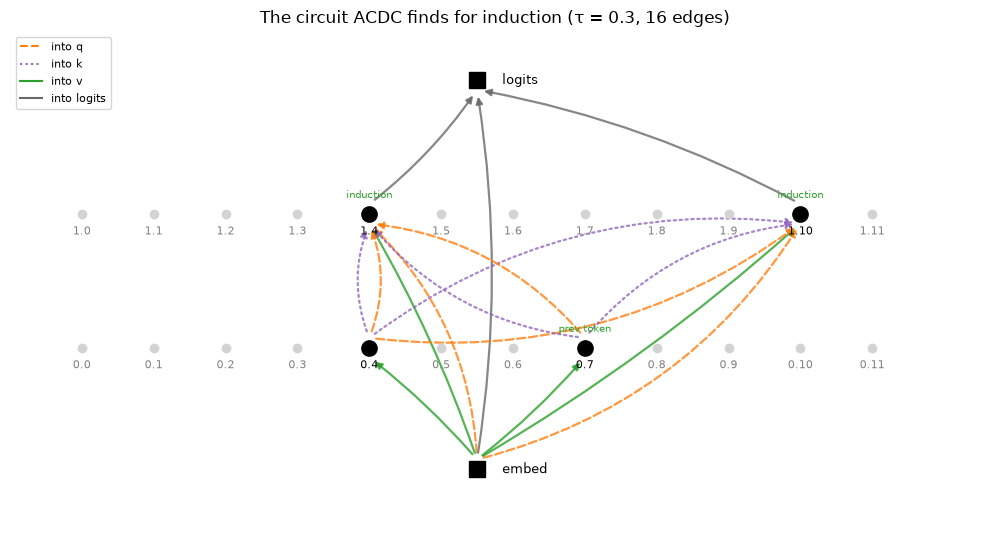

In [17]:
t0 = time.time()
circuit, n_tests = acdc(circuit_kl, EDGE_MASK, RECEIVER_ORDER, RECEIVER_OWNER, threshold=0.3)
print(f"ACDC tested {n_tests} of {int(EDGE_MASK.sum())} edges in {time.time() - t0:.1f}s and kept {int(circuit.sum())}")
print(f"KL = {circuit_kl(circuit):.3f}, held-out induction log prob = {circuit_logprob(circuit):.2f}\n")
for u, v in circuit.nonzero().tolist():
    print(f"  {SENDER_NAMES[u]:>6} -> {RECEIVER_NAMES[v]}")

ROLES_FROM_1_2 = {"0.7": "prev token", "1.4": "induction", "1.10": "induction"}
utils.draw_2l_circuit(circuit, SENDER_NAMES, RECEIVER_NAMES, f"The circuit ACDC finds for induction (τ = 0.3, {int(circuit.sum())} edges)", highlight=ROLES_FROM_1_2)

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">ACDC tested 109 of 529 edges in 4.6s and kept 16
KL = 3.311, held-out induction log prob = -8.66

   embed -&gt; 0.4&lt;v&gt;
   embed -&gt; 0.7&lt;v&gt;
   embed -&gt; 1.4&lt;q&gt;
   embed -&gt; 1.10&lt;q&gt;
   embed -&gt; 1.4&lt;v&gt;
   embed -&gt; 1.10&lt;v&gt;
   embed -&gt; logits
     0.4 -&gt; 1.4&lt;q&gt;
     0.4 -&gt; 1.10&lt;q&gt;
     0.4 -&gt; 1.4&lt;k&gt;
     0.4 -&gt; 1.10&lt;k&gt;
     0.7 -&gt; 1.4&lt;q&gt;
     0.7 -&gt; 1.4&lt;k&gt;
     0.7 -&gt; 1.10&lt;k&gt;
     1.4 -&gt; logits
    1.10 -&gt; logits</pre>

</details>

<details>
<summary>Question - compare this with the circuit you found in [1.2]. What's the same, and what's new?</summary>

**Everything from [1.2] is here.** The previous-token head 0.7 reads the token embedding through its value (`embed -> 0.7<v>`) and writes into the keys of both induction heads
(`0.7 -> 1.4<k>`, `0.7 -> 1.10<k>`): that's K-composition. The induction heads query with the current token (`embed -> 1.4<q>`, `embed -> 1.10<q>`), copy the attended token through
their values (`embed -> 1.4<v>`, `embed -> 1.10<v>`), and write to the logits. The direct path `embed -> logits` survives too. ACDC found all of this by deleting edges, with no
idea what an induction head is.

**What's new is head 0.4.** It reads the embedding through its value, and writes into both the keys *and* the queries of both induction heads. There's also `0.7 -> 1.4<q>`:
Q-composition from the previous-token head into one induction head's query. In [1.2] you mostly looked for K-composition, and these Q-composition edges weren't on the list.

Notice the cost of the threshold, though: this circuit's KL from the full model is 3.31 (the empty circuit's is 6.21), and its held-out log probability is −8.66 against the full
model's −3.23. With $\tau = 0.3$, ACDC has thrown away a lot of the behaviour, 0.3 nats at a time. Section 3️⃣ measures how much.
</details>

## What is head 0.4 doing?

ACDC has handed us a component we didn't put on our list in [1.2]. Before trusting it or dismissing it, let's look at it. In [1.2] you found previous-token heads by measuring how
much each head attends to the position right before the current one. Let's generalise that: for each layer-0 head, measure the average attention paid to the position $d$ steps
back, for $d = 0, 1, \ldots, 6$.

### Exercise - attention by offset

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵⚪⚪⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement `attention_by_offset`, which returns a tensor of shape `(n_heads, max_offset + 1)` whose entry `[h, d]` is head `h`'s attention from each position to the position `d`
steps earlier, averaged over prompts and over valid query positions from `max(start_pos, d)` onwards. For this exercise use `0 <= start_pos < seq_len` and `0 <= max_offset <
seq_len`. (`pattern.diagonal(offset=-d, dim1=-2, dim2=-1)` gives the attention from each position $i \geq d$ to position $i - d$.)

In [18]:
@t.no_grad()
def attention_by_offset(
    model: HookedTransformer, tokens: Int[Tensor, "batch seq"], layer: int, max_offset: int, start_pos: int = 8
) -> Float[Tensor, "n_heads offset"]:
    _, cache = model.run_with_cache(tokens, names_filter=f"blocks.{layer}.attn.hook_pattern")
    pattern = cache[f"blocks.{layer}.attn.hook_pattern"]  # (batch, head, query, key)
    # The diagonal at offset -d starts at query d. If d exceeds start_pos, keep the whole diagonal.
    return t.stack(
        [pattern.diagonal(offset=-d, dim1=-2, dim2=-1)[..., max(0, start_pos - d) :].mean(dim=(0, -1)) for d in range(max_offset + 1)],
        dim=-1,
    )

In [19]:
tests.test_attention_by_offset(attention_by_offset)

All tests in `test_attention_by_offset` passed!


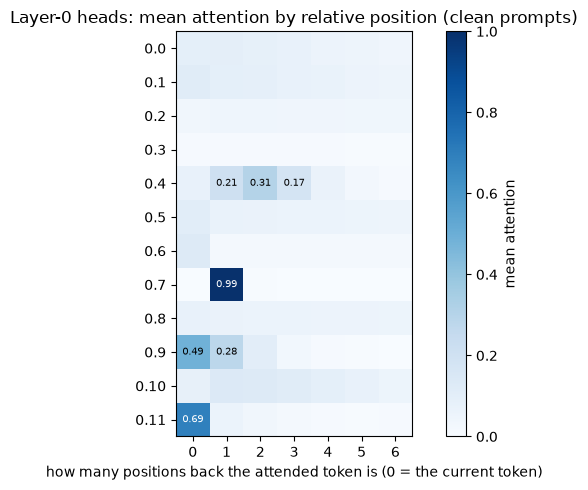

0.7: self 0.00, 1 back 0.99, 2 back 0.00, 3 back 0.00, 4 back 0.00, 5 back 0.00, 6 back 0.00
0.4: self 0.08, 1 back 0.21, 2 back 0.31, 3 back 0.17, 4 back 0.07, 5 back 0.02, 6 back 0.01
0.9: self 0.49, 1 back 0.28, 2 back 0.10, 3 back 0.03, 4 back 0.01, 5 back 0.01, 6 back 0.00


In [20]:
by_offset = attention_by_offset(model, clean, layer=0, max_offset=6).cpu()
fig, ax = plt.subplots(figsize=(7.5, 5))
im = ax.imshow(by_offset, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(7), [str(d) for d in range(7)])
ax.set_yticks(range(N_HEADS), [f"0.{h}" for h in range(N_HEADS)])
for h in range(N_HEADS):
    for d in range(7):
        if by_offset[h, d] > 0.15:
            ax.text(d, h, f"{by_offset[h, d]:.2f}", ha="center", va="center", fontsize=7, color="white" if by_offset[h, d] > 0.5 else "black")
ax.set_xlabel("how many positions back the attended token is (0 = the current token)")
ax.set_title("Layer-0 heads: mean attention by relative position (clean prompts)")
fig.colorbar(im, ax=ax, label="mean attention", fraction=0.04)
plt.tight_layout()
plt.show()
for h in [7, 4, 9]:
    print(f"0.{h}: " + ", ".join(f"{label} {v:.2f}" for label, v in zip(["self"] + [f"{d} back" for d in range(1, 7)], by_offset[h].tolist())))

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">0.7: self 0.00, 1 back 0.99, 2 back 0.00, 3 back 0.00, 4 back 0.00, 5 back 0.00, 6 back 0.00
0.4: self 0.08, 1 back 0.21, 2 back 0.31, 3 back 0.17, 4 back 0.07, 5 back 0.02, 6 back 0.01
0.9: self 0.49, 1 back 0.28, 2 back 0.10, 3 back 0.03, 4 back 0.01, 5 back 0.01, 6 back 0.00</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

0.7 is a textbook previous-token head: 0.99 of its attention goes exactly one position back. Head 0.4 is something else. It spreads its attention over the last few tokens, with
most of it on the token *two* positions back (0.31), then one back (0.21) and three back (0.17). So 0.4's output at position $i$ is a blurry summary of tokens $i-1$ to $i-3$,
rather than a clean copy of token $i-1$.

That suggests a role. Written into an induction head's key at position $j$, it says "the tokens before me were roughly these"; written into the query at position $i$, it says the
same about the tokens before the current one. If those match, it's evidence that the current token is preceded by the same *context* as last time, not just that it's the same
token. That's a fuzzier, multi-token version of induction, and it would help the induction heads attend to the right occurrence.

Is that what's happening? We haven't shown it. The bonus section suggests an experiment that would. It's also worth noticing what *didn't* get into the circuit: head 0.9 has a
higher previous-token score (0.28) than 0.4 (0.21), but it attends mostly to the current token (0.49), and ACDC removed all of its edges. A previous-token score alone wouldn't have
told you which of these two heads matters.
</details>

## Choosing the threshold

$\tau$ is ACDC's only knob, and it trades size against faithfulness. Let's sweep it, and for each threshold record the number of edges, the KL on the discovery prompts, and the
induction log probability on the held-out prompts.

We'll compare with two baselines at the same sizes:

- **Single-edge ranking**: keep the $k$ edges with the largest single-edge effect from section 1️⃣. This is what you'd get from activation patching without recomputation.
- **Random circuits**: $k$ edges chosen uniformly at random from the 529. Any method that doesn't beat this isn't telling you anything.

### Exercise - random circuits, and the single-edge baseline

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement `random_circuit`, which returns a circuit with exactly `n_edges` edges, chosen uniformly at random from the valid edges using `generator`, and `top_k_circuit`, which
keeps the `k` valid edges with the largest `scores`.

In [21]:
def random_circuit(edge_mask: Tensor, n_edges: int, generator: t.Generator) -> Bool[Tensor, "sender receiver"]:
    valid = edge_mask.flatten().nonzero().flatten()
    chosen = valid[t.randperm(len(valid), generator=generator)[:n_edges]]
    circuit = t.zeros(edge_mask.numel(), dtype=t.bool)
    circuit[chosen] = True
    return circuit.reshape(edge_mask.shape)


def top_k_circuit(scores: Tensor, edge_mask: Tensor, k: int) -> Bool[Tensor, "sender receiver"]:
    flat = scores.float().masked_fill(~edge_mask, -float("inf")).flatten()
    circuit = t.zeros(edge_mask.numel(), dtype=t.bool)
    circuit[flat.topk(k).indices] = True
    return circuit.reshape(edge_mask.shape)


tests.test_random_circuit(random_circuit, EDGE_MASK)

All tests in `test_random_circuit` passed!


In [22]:
tests.test_top_k_circuit(top_k_circuit)

All tests in `test_top_k_circuit` passed!


thresholds:   0%|          | 0/6 [00:00<?, ?it/s]

   tau  edges  tested  KL (ACDC)  KL (single-edge top-k)  KL (random, median)
   1.0      3     103      5.005                   6.248                6.211
   0.3     16     109      3.311                   4.112                6.211
   0.1     33     424      2.229                   3.194                6.211
  0.03     60     511      1.162                   1.629                6.174
  0.01     97     517      0.690                   0.866                6.129
 0.003    207     526      0.307                   0.329                5.629


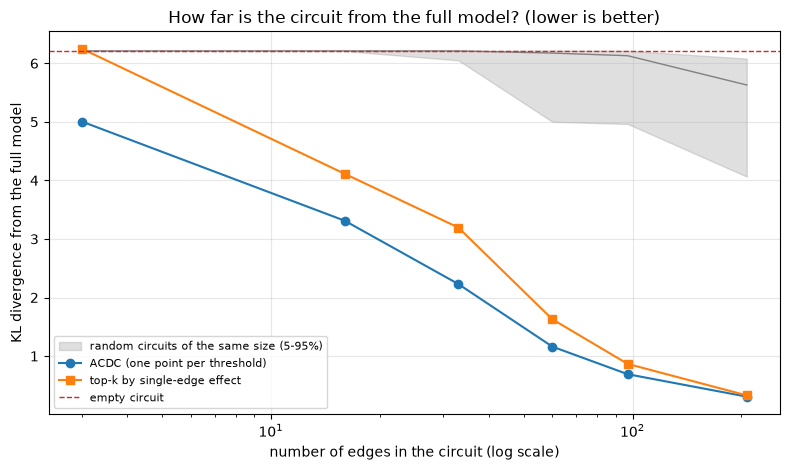

In [23]:
THRESHOLDS = [1.0, 0.3, 0.1, 0.03, 0.01, 0.003]
sweep = {}
for tau in tqdm(THRESHOLDS, desc="thresholds"):
    found, n_tested = acdc(circuit_kl, EDGE_MASK, RECEIVER_ORDER, RECEIVER_OWNER, threshold=tau)
    sweep[tau] = {"circuit": found, "edges": int(found.sum()), "tested": n_tested, "kl": circuit_kl(found), "logprob": circuit_logprob(found)}

generator = t.Generator().manual_seed(0)
sizes = [sweep[tau]["edges"] for tau in THRESHOLDS]
single_kls = [circuit_kl(top_k_circuit(single_kl, EDGE_MASK, k)) for k in sizes]
random_kls = [[circuit_kl(random_circuit(EDGE_MASK, k, generator)) for _ in range(20)] for k in sizes]

print(f"{'tau':>6} {'edges':>6} {'tested':>7} {'KL (ACDC)':>10} {'KL (single-edge top-k)':>23} {'KL (random, median)':>20}")
for tau, s_kl, r_kls in zip(THRESHOLDS, single_kls, random_kls):
    row = sweep[tau]
    print(f"{tau:>6} {row['edges']:>6} {row['tested']:>7} {row['kl']:>10.3f} {s_kl:>23.3f} {np.median(r_kls):>20.3f}")

utils.plot_size_vs_metric(
    {"ACDC (one point per threshold)": (sizes, [sweep[tau]["kl"] for tau in THRESHOLDS]), "top-k by single-edge effect": (sizes, single_kls)},
    title="How far is the circuit from the full model? (lower is better)",
    ylabel="KL divergence from the full model",
    random_band=(sizes, [np.percentile(r, 5) for r in random_kls], [np.median(r) for r in random_kls], [np.percentile(r, 95) for r in random_kls]),
    reference={"empty circuit": circuit_kl(EMPTY)},
)

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">   tau  edges  tested  KL (ACDC)  KL (single-edge top-k)  KL (random, median)
   1.0      3     103      5.005                   6.248                6.211
   0.3     16     109      3.311                   4.112                6.211
   0.1     33     424      2.229                   3.194                6.211
  0.03     60     511      1.162                   1.629                6.174
  0.01     97     517      0.690                   0.866                6.129
 0.003    207     526      0.307                   0.329                5.629</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

**The threshold controls the trade-off smoothly.** From $\tau = 1$ (3 edges, KL 5.0) to $\tau = 0.003$ (207 edges, KL 0.31), each tenfold drop in the threshold buys a circuit
that's several times larger and closer to the full model.

**ACDC beats the one-shot baseline at every size,** and by a wide margin for small circuits: at 16 edges, the top 16 single-edge effects give KL 4.11 against ACDC's 3.31, and at 33
edges 3.19 against 2.23. Single-edge effects are measured with everything else intact, so they can't see that some edges only matter together, or that some important-looking edges
are redundant given others. ACDC's recomputation can.

**Random circuits are far worse:** up to 97 edges they're indistinguishable from the empty circuit (KL 6.2), and even 207 random edges leave the KL at 5.6 (median). That's the
baseline any discovery method has to beat, and it's beaten by a lot.

Also look at the `tested` column: at $\tau = 1$ and $\tau = 0.3$ ACDC tested only about 100 of 529 edges, because once the logits had lost their edges from most heads, those heads'
inputs were dropped without testing.
</details>

## Summary of 2️⃣

- ACDC removes edges greedily from the output backwards, keeping a removal whenever it changes the metric of the *current* circuit by less than $\tau$, and drops the inputs of any node that has left the circuit.
- On the two-layer model it recovers the induction circuit from [1.2] (previous-token head → induction heads' keys; embedding → induction heads' queries and values) with no prior knowledge, and adds a head (0.4) that attends to the last few tokens and feeds both the queries and the keys of the induction heads.
- The threshold bounds each step, not the total: at $\tau = 0.3$, a 16-edge circuit sits far from the full model in KL, even though no single removal cost more than 0.3.
- ACDC beats ranking edges by their single-edge effects at every circuit size, because it measures each edge in the context of the current circuit; and random circuits of the same size recover essentially nothing.

# 3️⃣ Is It the Right Circuit?

> ##### Learning Objectives
>
> - Compute normalised faithfulness on held-out prompts, and compare against same-size random circuits
> - Implement the completeness test of Wang et al. and read its scatter plot
> - Measure per-edge minimality and see how it changes with the threshold
> - Understand what an ROC curve against a reference circuit measures, and how much it depends on the reference

## Faithfulness

ACDC was told to minimise KL on the discovery prompts, so measuring its KL on those prompts is marking its own homework. For evaluation we use the **task metric** (induction log
probability) on **held-out** prompts, normalised so that the full model scores 1 and the empty circuit scores 0:

$$
F(C) = \frac{m(C) - m(\varnothing)}{m(M) - m(\varnothing)}
$$

where $m$ is the metric, $M$ is the full model and $\varnothing$ is the empty circuit (every edge carrying corrupted values). This is the "normalised faithfulness" used throughout
the circuit-discovery literature. It can be negative (the circuit is worse than nothing) or above 1 (the circuit is better at the task than the model, which happens when the
circuit drops components that were *hurting* performance).

### Exercise - faithfulness

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5 minutes on this exercise.
> ```

In [24]:
def faithfulness(value: float, full: float, empty: float) -> float:
    """Normalised faithfulness: 1 for the full model, 0 for the empty circuit."""
    return (value - empty) / (full - empty)


tests.test_faithfulness(faithfulness)

All tests in `test_faithfulness` passed!


 edges    ACDC  single-edge top-k   random (median, 95th pct)
     3    0.05              -0.00           0.00, 0.00
    16    0.47               0.26           0.00, 0.03
    33    0.69               0.38           0.00, 0.05
    60    0.86               0.71           0.00, 0.05
    97    0.93               0.88           0.00, 0.05
   207    0.96               0.94           0.04, 0.08


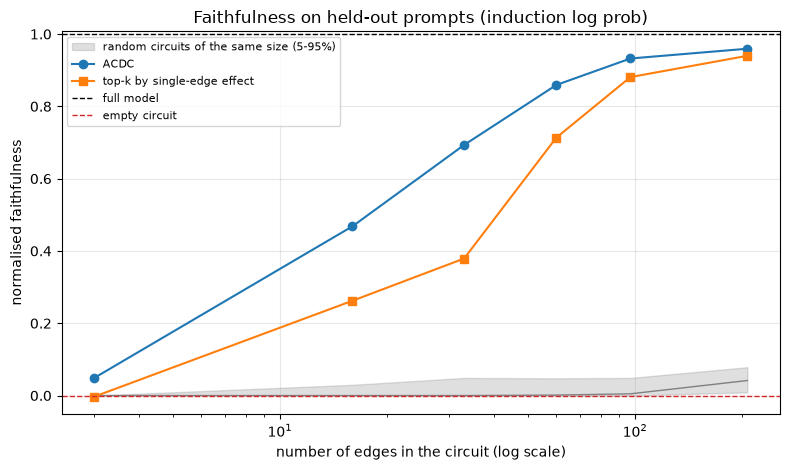

In [25]:
LP_FULL, LP_EMPTY = circuit_logprob(EDGE_MASK), circuit_logprob(EMPTY)


def circuit_faithfulness(circuit: Tensor) -> float:
    return faithfulness(circuit_logprob(circuit), LP_FULL, LP_EMPTY)


acdc_faith = [circuit_faithfulness(sweep[tau]["circuit"]) for tau in THRESHOLDS]
single_faith = [circuit_faithfulness(top_k_circuit(single_kl, EDGE_MASK, k)) for k in sizes]
generator = t.Generator().manual_seed(1)
random_faith = [[circuit_faithfulness(random_circuit(EDGE_MASK, k, generator)) for _ in range(50)] for k in sizes]

print(f"{'edges':>6} {'ACDC':>7} {'single-edge top-k':>18} {'random (median, 95th pct)':>27}")
for k, a, s, r in zip(sizes, acdc_faith, single_faith, random_faith):
    print(f"{k:>6} {a:>7.2f} {s:>18.2f} {np.median(r):>14.2f}, {np.percentile(r, 95):.2f}")

utils.plot_size_vs_metric(
    {"ACDC": (sizes, acdc_faith), "top-k by single-edge effect": (sizes, single_faith)},
    title="Faithfulness on held-out prompts (induction log prob)",
    ylabel="normalised faithfulness",
    random_band=(sizes, [np.percentile(r, 5) for r in random_faith], [np.median(r) for r in random_faith], [np.percentile(r, 95) for r in random_faith]),
    reference={"full model": 1.0, "empty circuit": 0.0},
)

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace"> edges    ACDC  single-edge top-k   random (median, 95th pct)
     3    0.05              -0.00           0.00, 0.00
    16    0.47               0.26           0.00, 0.03
    33    0.69               0.38           0.00, 0.05
    60    0.86               0.71           0.00, 0.05
    97    0.93               0.88           0.00, 0.05
   207    0.96               0.94           0.04, 0.08</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

This is the same story as the KL plot, now on held-out prompts and with the task metric, which is the version you'd report. ACDC's 16-edge circuit recovers 47% of the induction
performance, its 33-edge circuit 69%, and its 97-edge circuit 93%. The single-edge ranking needs about twice as many edges for the same faithfulness at small sizes. Random circuits
stay at essentially zero up to 97 edges (their 95th percentile is 0.05), so the gap isn't a fluke of which random edges you draw.

The difference between "16 edges, 47%" and "97 edges, 93%" is a real choice you'd have to make when reporting a circuit. The 16-edge circuit is the one you can read; the 97-edge
one is the one that actually reproduces the behaviour. There's no threshold that gives you both here, and a paper that reports only one of them is telling you half the story.
</details>

## Completeness

Faithfulness asks whether the circuit is *enough*. **Completeness** asks whether it's *everything*: is there another route through the model that also does the job, which the
circuit left out? A circuit can be perfectly faithful and still incomplete, if the model contains redundant copies of a mechanism and the circuit kept only one. (The IOI paper's
backup name movers, which you met in [8.1], are the classic example.)

Wang et al. (2022) proposed a test. Take a subset $K$ of the circuit's components and knock it out of both the circuit and the full model. If the circuit is complete, the two
should suffer equally: $F(C \setminus K) \approx F(M \setminus K)$. If the full model holds up much better than the circuit when $K$ is removed, something outside the circuit is
taking over $K$'s job.

At the edge level, "knocking $K$ out of the full model" means cutting the edges in $K$ while keeping every edge outside the circuit. We'll sample random subsets $K$ containing
about a quarter of the circuit's edges.

### Exercise - the completeness test

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵🔵⚪
> 
> You should spend up to 10-15 minutes on this exercise.
> ```

Implement `completeness_scores`. For each of `n_subsets` random subsets $K$ of the circuit's edges (include each edge independently with probability `frac`, using `generator`),
compute the faithfulness of the circuit without $K$, and of the full model without $K$. Return two tensors of length `n_subsets`.

In [26]:
def completeness_scores(
    circuit: Tensor, edge_mask: Tensor, faith_fn: Callable[[Tensor], float], n_subsets: int, frac: float, generator: t.Generator
) -> tuple[Float[Tensor, " n"], Float[Tensor, " n"]]:
    circuit_scores, model_scores = [], []
    for _ in range(n_subsets):
        knockout = circuit & (t.rand(circuit.shape, generator=generator) < frac)
        circuit_scores.append(faith_fn(circuit & ~knockout))
        model_scores.append(faith_fn(edge_mask & ~knockout))
    return t.tensor(circuit_scores), t.tensor(model_scores)

In [27]:
tests.test_completeness_scores(completeness_scores)

All tests in `test_completeness_scores` passed!


ACDC circuit (τ = 0.1, 33 edges): mean F(M\K) - F(C\K) = +0.110, largest gap = +0.364
Random circuit of the same size:   mean F(M\K) - F(C\K) = +0.867


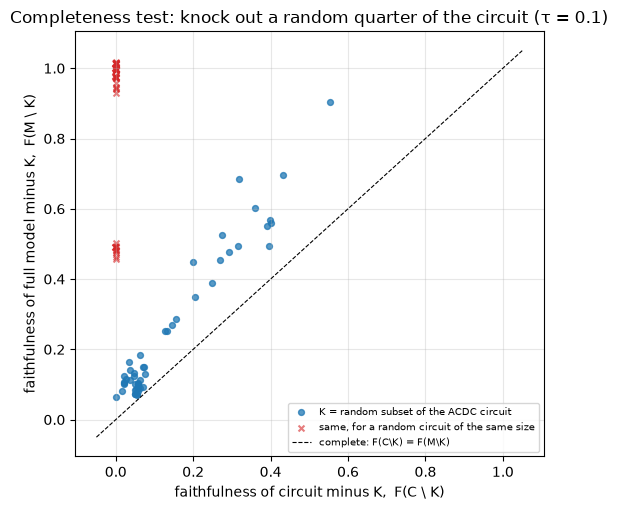

In [28]:
TAU = 0.1
chosen = sweep[TAU]["circuit"]
generator = t.Generator().manual_seed(2)
c_scores, m_scores = completeness_scores(chosen, EDGE_MASK, circuit_faithfulness, n_subsets=50, frac=0.25, generator=generator)
rand = random_circuit(EDGE_MASK, int(chosen.sum()), generator)
rc_scores, rm_scores = completeness_scores(rand, EDGE_MASK, circuit_faithfulness, n_subsets=50, frac=0.25, generator=generator)

gap = (m_scores - c_scores)
print(f"ACDC circuit (τ = {TAU}, {int(chosen.sum())} edges): mean F(M\\K) - F(C\\K) = {gap.mean():+.3f}, largest gap = {gap.max():+.3f}")
print(f"Random circuit of the same size:   mean F(M\\K) - F(C\\K) = {(rm_scores - rc_scores).mean():+.3f}")
utils.plot_completeness(c_scores, m_scores, (rc_scores, rm_scores), f"Completeness test: knock out a random quarter of the circuit (τ = {TAU})")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">ACDC circuit (τ = 0.1, 33 edges): mean F(M\K) - F(C\K) = +0.110, largest gap = +0.364
Random circuit of the same size:   mean F(M\K) - F(C\K) = +0.867</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

If the ACDC circuit were complete, the blue points would lie on the diagonal. They lie above it, consistently: when we knock a random quarter of the circuit out, the full model
loses less than the circuit does (on average its faithfulness is 0.11 higher, and up to 0.36 higher for some subsets). Some of the circuit's work is *also* done by edges outside
it, and the full model falls back on them. That's backup or redundant computation, the same phenomenon as IOI's backup name movers, at a smaller scale. The 33-edge circuit at $\tau
= 0.1$ is faithful enough to matter (0.69), but it isn't complete.

The random circuit (red) is the control, and it fails dramatically: removing parts of it destroys the circuit (it had nothing to start with) while the full model barely notices,
because the parts that matter aren't in it. Its points sit high on the left edge of the plot, far from the diagonal (mean gap 0.87). The two clusters of red points are the subsets
that do and don't happen to include one important edge.

Notice how this test complements faithfulness. Faithfulness asks whether the circuit is enough; completeness asks whether it's all there is, and a circuit can pass the first and
fail the second.
</details>

## Minimality

The last question is whether every edge in the circuit earns its place. For each edge $e \in C$, remove it alone and see how much faithfulness drops: $F(C) - F(C \setminus \{e\})$.
In a minimal circuit every drop is clearly positive. Edges with drops near zero (or negative) are passengers.

ACDC's threshold makes a specific promise here, about *KL on the discovery prompts* and only at the moment each edge was tested: removing it would have raised KL by at least
$\tau$. Later removals change the context, and our evaluation metric is a different one, so the promise needn't carry over.

### Exercise - per-edge drops

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 5-10 minutes on this exercise.
> ```

Implement `edge_drops`, returning for each edge of the circuit (in the order of `circuit.nonzero()`) the drop in `faith_fn` when that edge alone is removed.

In [29]:
def edge_drops(circuit: Tensor, faith_fn: Callable[[Tensor], float]) -> Float[Tensor, " n_edges"]:
    base = faith_fn(circuit)
    drops = []
    for u, v in circuit.nonzero().tolist():
        smaller = circuit.clone()
        smaller[u, v] = False
        drops.append(base - faith_fn(smaller))
    return t.tensor(drops)

In [30]:
tests.test_edge_drops(edge_drops)

All tests in `test_edge_drops` passed!


ACDC, τ = 0.3 :  16 edges,   0 with drop < 0.01, smallest drop +0.046, largest +0.414
ACDC, τ = 0.1 :  33 edges,  10 with drop < 0.01, smallest drop -0.001, largest +0.632
ACDC, τ = 0.03:  60 edges,  31 with drop < 0.01, smallest drop -0.014, largest +0.806


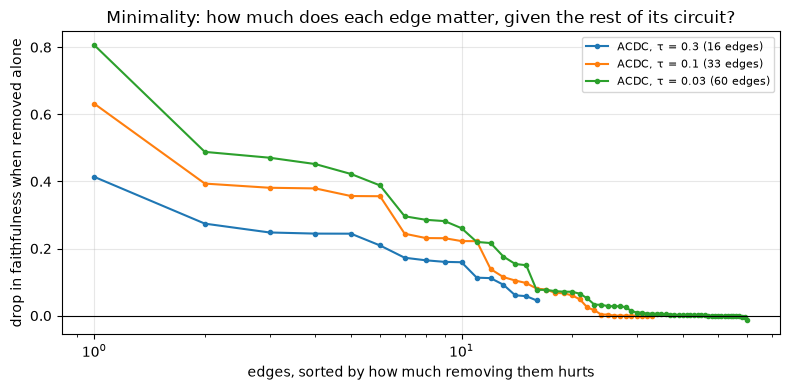

In [31]:
drops = {f"ACDC, τ = {tau}": edge_drops(sweep[tau]["circuit"], circuit_faithfulness) for tau in [0.3, 0.1, 0.03]}
for name, d in drops.items():
    print(f"{name:<14}: {len(d):>3} edges, {int((d < 0.01).sum()):>3} with drop < 0.01, smallest drop {d.min():+.3f}, largest {d.max():+.3f}")
utils.plot_minimality(drops, "Minimality: how much does each edge matter, given the rest of its circuit?")

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">ACDC, τ = 0.3 :  16 edges,   0 with drop &lt; 0.01, smallest drop +0.046, largest +0.414
ACDC, τ = 0.1 :  33 edges,  10 with drop &lt; 0.01, smallest drop -0.001, largest +0.632
ACDC, τ = 0.03:  60 edges,  31 with drop &lt; 0.01, smallest drop -0.014, largest +0.806</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

At $\tau = 0.3$ the circuit is minimal: all 16 edges matter, the least important still costs 0.05 of faithfulness when removed. As the threshold drops, passengers appear: 10 of the
33 edges at $\tau = 0.1$ and 31 of the 60 at $\tau = 0.03$ cost less than 0.01 each, and a few have slightly *negative* drops (removing them helps).

That's not a bug in ACDC. Each of those edges was kept because, at the moment it was tested, removing it would have raised the *KL on the discovery prompts* by more than $\tau$.
Our minimality test uses a different metric (the induction log probability) on different prompts, and tests each edge given the *final* circuit. KL cares about the whole next-token
distribution, so ACDC keeps edges that shape probabilities on tokens other than the right answer; the task metric ignores those. It's a reminder that "minimal" is always minimal
*with respect to a metric*.
</details>

## Comparing against a known answer

The ACDC paper's headline evaluation is different from all of the above: it compares the edges a method finds with a **reference circuit** found by hand, and plots an ROC curve as
the threshold varies (true positive rate: the fraction of reference edges recovered; false positive rate: the fraction of non-reference edges included).

Our reference is the circuit from [1.2], written as edges:

In [32]:
REFERENCE_EDGES = [
    ("embed", "0.7<v>"),  # the previous-token head moves the previous token...
    ("0.7", "1.4<k>"), ("0.7", "1.10<k>"),  # ...into the induction heads' keys (K-composition)
    ("embed", "1.4<q>"), ("embed", "1.10<q>"),  # the induction heads query with the current token
    ("embed", "1.4<v>"), ("embed", "1.10<v>"),  # and copy the token they attend to
    ("1.4", "logits"), ("1.10", "logits"),
    ("embed", "logits"),  # the direct path (bigram statistics), which any faithful circuit needs
]
REFERENCE = t.zeros_like(EDGE_MASK)
for s, r in REFERENCE_EDGES:
    REFERENCE[SENDER_NAMES.index(s), RECEIVER_NAMES.index(r)] = True
print(f"Reference circuit: {int(REFERENCE.sum())} edges")

Reference circuit: 10 edges


### Exercise - ROC points

> ```yaml
> Difficulty: 🔴⚪⚪⚪⚪
> Importance: 🔵🔵⚪⚪⚪
> 
> You should spend up to 5 minutes on this exercise.
> ```

Implement `roc_point`, which returns `(false positive rate, true positive rate)` of a circuit against a reference, counting only valid edges.

In [33]:
def roc_point(circuit: Tensor, reference: Tensor, edge_mask: Tensor) -> tuple[float, float]:
    circuit, reference = circuit & edge_mask, reference & edge_mask
    tpr = (circuit & reference).sum() / reference.sum()
    fpr = (circuit & ~reference).sum() / (edge_mask & ~reference).sum()
    return fpr.item(), tpr.item()


tests.test_roc_point(roc_point)

All tests in `test_roc_point` passed!


ACDC τ = 1.0    edges =   3  TPR = 0.30  FPR = 0.000
ACDC τ = 0.3    edges =  16  TPR = 1.00  FPR = 0.012
ACDC τ = 0.1    edges =  33  TPR = 1.00  FPR = 0.044
ACDC τ = 0.03   edges =  60  TPR = 1.00  FPR = 0.096
ACDC τ = 0.01   edges =  97  TPR = 1.00  FPR = 0.168
ACDC τ = 0.003  edges = 207  TPR = 1.00  FPR = 0.380


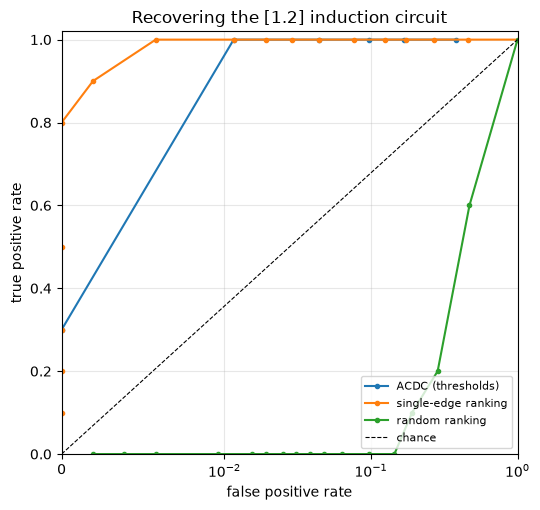

In [34]:
acdc_roc = [roc_point(sweep[tau]["circuit"], REFERENCE, EDGE_MASK) for tau in THRESHOLDS]
ks = [1, 2, 3, 5, 8, 10, 13, 16, 20, 25, 33, 50, 75, 100, 150, 250, 529]
single_roc = [roc_point(top_k_circuit(single_kl, EDGE_MASK, k), REFERENCE, EDGE_MASK) for k in ks]
generator = t.Generator().manual_seed(3)
random_scores = t.rand(EDGE_MASK.shape, generator=generator)
random_roc = [roc_point(top_k_circuit(random_scores, EDGE_MASK, k), REFERENCE, EDGE_MASK) for k in ks]

for tau, (fpr, tpr) in zip(THRESHOLDS, acdc_roc):
    print(f"ACDC τ = {tau:<6} edges = {sweep[tau]['edges']:>3}  TPR = {tpr:.2f}  FPR = {fpr:.3f}")
utils.plot_roc(
    {"ACDC (thresholds)": tuple(zip(*acdc_roc)), "single-edge ranking": tuple(zip(*single_roc)), "random ranking": tuple(zip(*random_roc))},
    "Recovering the [1.2] induction circuit",
)

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">ACDC τ = 1.0    edges =   3  TPR = 0.30  FPR = 0.000
ACDC τ = 0.3    edges =  16  TPR = 1.00  FPR = 0.012
ACDC τ = 0.1    edges =  33  TPR = 1.00  FPR = 0.044
ACDC τ = 0.03   edges =  60  TPR = 1.00  FPR = 0.096
ACDC τ = 0.01   edges =  97  TPR = 1.00  FPR = 0.168
ACDC τ = 0.003  edges = 207  TPR = 1.00  FPR = 0.380</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

ACDC recovers every reference edge from $\tau = 0.3$ downwards, with a false positive rate of 1.2% (the 6 edges in its 16-edge circuit that aren't in the reference). Random ranking
does no better than chance.

But look at the single-edge ranking: it reaches a true positive rate of 0.8 with *no* false positives, and finds all 10 reference edges at a false positive rate well below 1%. **By
this metric, the simple baseline beats ACDC.** Yet by faithfulness, ACDC was clearly better. How can both be true?

Because the ROC curve measures agreement with *our reference*, and the reference is what we wrote down in [1.2]: the K-composition mechanism plus the direct path. The edges ACDC
adds beyond it (head 0.4's inputs to the induction heads' queries and keys, and the Q-composition edge from 0.7) count as false positives, but they're exactly the edges that make
ACDC's circuit more faithful. The single-edge ranking happens to agree with the reference because the reference edges are each individually important; the extra edges only matter
together.

The lesson is about evaluation, not about which method is better. An ROC curve against a hand-made circuit rewards agreeing with the hand-made circuit, including its omissions. The
ACDC paper's ROC curves inherit this, and the papers that benchmark circuit discovery on models with a *known* ground truth (compiled transformers, which you'll meet in [8.8])
exist for exactly this reason.
</details>

## Try it yourself - change the question

A circuit is an answer to a question, and the question is set by the corruption and the metric. Below, ACDC is rerun with a **different corruption**: instead of fresh random tokens
everywhere, the corrupted prompt repeats a *different* random sequence, $[\text{BOS}, s_1..s_n, s_1..s_n]$. Induction still happens on the corrupted prompt; it just predicts the
wrong tokens.

Before running it: which edges do you expect to survive now? Think about which senders carry *different* information in the two runs, and which carry the same kind of information.

Other things to try: use `circuit_logprob`-based metric (the negative log prob on the discovery prompts) instead of KL inside ACDC; change the order of senders within a receiver
(`edge_mask[:, v].nonzero()` without `reversed`); or shrink the dataset to 8 prompts and see how stable the circuit is.

In [35]:
generator = t.Generator().manual_seed(10)
other = t.randint(1000, 10000, (clean.shape[0], HALF_LEN), generator=generator).to(device)
corrupt_repeat = t.cat([clean[:, :1], other, other], dim=1)
corrupt_repeat_out = sender_outputs(model, corrupt_repeat)


@t.inference_mode()
def circuit_kl_repeat(circuit: Tensor) -> float:
    return kl_divergence(run_graph(model, clean, corrupt_repeat_out, circuit)[:, INDUCTION_POS], full_logprobs).item()


play_circuit, play_tested = acdc(circuit_kl_repeat, EDGE_MASK, RECEIVER_ORDER, RECEIVER_OWNER, threshold=0.3)
print(f"{int(play_circuit.sum())} edges (tested {play_tested}); KL = {circuit_kl_repeat(play_circuit):.3f}")
print("In this circuit but not the original:", [f"{SENDER_NAMES[u]}->{RECEIVER_NAMES[v]}" for u, v in (play_circuit & ~circuit).nonzero().tolist()])
print("In the original but not this one:   ", [f"{SENDER_NAMES[u]}->{RECEIVER_NAMES[v]}" for u, v in (circuit & ~play_circuit).nonzero().tolist()])

13 edges (tested 148); KL = 2.648
In this circuit but not the original: ['1.5->logits']
In the original but not this one:    ['embed->0.4<v>', '0.4->1.4<k>', '0.4->1.10<k>', '0.7->1.4<q>']


<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">13 edges (tested 148); KL = 2.648
In this circuit but not the original: ['1.5-&gt;logits']
In the original but not this one:    ['embed-&gt;0.4&lt;v&gt;', '0.4-&gt;1.4&lt;k&gt;', '0.4-&gt;1.10&lt;k&gt;', '0.7-&gt;1.4&lt;q&gt;']</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

With the repeated corruption, ACDC returns a smaller circuit (13 edges). The core mechanism is unchanged (0.7 into the induction heads' keys, the embedding into their queries and
values, the induction heads into the logits), but most of what head 0.4 contributed is gone: its value input from the embedding, and its edges into the induction heads' keys. So is
the Q-composition edge `0.7 -> 1.4<q>`.

Why? Cutting an edge replaces its sender's output with the output on the corrupted prompt, so an edge only looks important if the corrupted output is *different in a way that
matters*. The circuit you find is always a circuit *for the contrast between the clean and corrupted prompts*, not for the behaviour in the abstract. Change the contrast and you
change the answer.

Look closely and you'll find an artifact, too. The circuit still contains `0.4 -> 1.4<q>` and `0.4 -> 1.10<q>`, but none of head 0.4's *inputs* survived, so 0.4's output in this
circuit is exactly its output on the corrupted prompt, and those two edges carry nothing. ACDC kept them because it tested them first (it works backwards from the output), when
0.4's input was still intact; by the time it cut 0.4's input, it never went back. Implementations of ACDC usually finish with a clean-up pass that removes nodes with no remaining
path from the input. Can you write one?
</details>

## Summary of 3️⃣

- Evaluate a circuit on held-out prompts with a task metric, and compare it with random circuits of the same size. ACDC's circuits recover far more than random ones (which recover nothing) and more than the single-edge ranking at every size.
- Faithfulness, completeness and minimality answer different questions. ACDC's 33-edge circuit is reasonably faithful (0.69) but not complete: the rest of the model can partly compensate when parts of it are removed.
- Minimality is relative to a metric. Circuits found by minimising KL contain edges that hardly matter for the task metric, more of them at lower thresholds.
- An ROC curve against a hand-made reference measures agreement with the reference, including its omissions. On induction, the single-edge ranking agrees with our reference better than ACDC does, even though ACDC's circuits are more faithful.
- The circuit depends on the corruption: a different contrast between clean and corrupted prompts gives a different circuit.

# 4️⃣ ACDC on GPT-2: Greater-Than

> ##### Learning Objectives
>
> - Apply ACDC to a real 12-layer model, and understand where its cost comes from
> - Compare an automatically discovered circuit with a hand-found one, component by component
> - Check faithfulness on held-out prompts against same-size random circuits

In [8.2] you built the edge graph of GPT-2 Small: one sender for the input embedding, one for each of the 144 heads and one for each of the 12 MLPs; one receiver for each head's
query, key and value input, one for each MLP's input, and one for the logits. You also wrote `run_with_circuit`, a forward pass that cuts any set of edges using TransformerLens
hooks. That's everything ACDC needs, and your `acdc` function doesn't care which model it's running on. (Since `run_with_circuit` was an exercise in [8.2],
`utils.gpt2_circuit_logits` is a copy of it that returns the final-position logits instead of a metric.)

The task is **greater-than** (Hanna, Liu & Variengien, 2023), which you met in [8.1] and [8.2]: GPT-2 should continue `"The war lasted from the year 1732 to the year 17"` with a
two-digit year greater than 32. The corrupted prompt replaces the start year with `1701`. By patching and attention analysis, Hanna et al. found a circuit with two stages:

- attention heads **5.1, 5.5, 6.1, 6.9, 7.10, 8.8, 8.11 and 9.1** attend from the final position to the start year and move information about it to the final position;
- **MLPs 8, 9, 10 and 11** turn that into higher probabilities for the years greater than it.

The ACDC paper ran its algorithm on exactly this task, and that's what we'll do now.

One thing to notice before we start: the graph has 32,491 edges, and testing one edge costs a forward pass. If ACDC tested them all, this would take hours. What saves it is the
rule you implemented for nodes that have left the circuit: once a head has no outgoing edges left, its 300-odd input edges are dropped without being tested.

In [36]:
gpt2 = HookedTransformer.from_pretrained("gpt2-small", device=device)
gpt2.requires_grad_(False)
gpt2.set_use_split_qkv_input(True)  # needed to cut edges into individual heads' q, k and v inputs
gpt2.set_use_hook_mlp_in(True)
GPT2_EDGES = gpt2_graph.EDGE_MASK

gt = gpt2_graph.make_greater_than_task(gpt2, 64, seed=0)
gt_heldout = gpt2_graph.make_greater_than_task(gpt2, 64, seed=1)
print(gpt2.to_string(gt.clean_tokens[0, 1:]), "|", gpt2.to_string(gt.corrupt_tokens[0, 1:]))
print(f"{gpt2_graph.N_SENDERS} senders, {gpt2_graph.N_RECEIVERS} receivers, {int(GPT2_EDGES.sum()):,} edges")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loaded pretrained model gpt2-small into HookedTransformer
The revolution lasted from the year 1455 to the year 14 | The revolution lasted from the year 1401 to the year 14
157 senders, 445 receivers, 32,491 edges


<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">The revolution lasted from the year 1455 to the year 14 | The revolution lasted from the year 1401 to the year 14
157 senders, 445 receivers, 32,491 edges</pre>

</details>

### Exercise - the receiver order for GPT-2

> ```yaml
> Difficulty: 🔴🔴⚪⚪⚪
> Importance: 🔵🔵🔵⚪⚪
> 
> You should spend up to 10 minutes on this exercise.
> ```

Write `gpt2_receiver_order` and `gpt2_receiver_owner` for the [8.2] graph, using its index helpers (`gpt2_graph.head_receiver(layer, qkv, head)`, `gpt2_graph.mlp_receiver(layer)`,
`gpt2_graph.head_sender(layer, head)`, `gpt2_graph.mlp_sender(layer)` and `gpt2_graph.LOGITS_RECEIVER`).

The order must be reverse-topological: a receiver can only be processed after every receiver that its node sends to. Within a layer, the MLP reads the residual stream *after* the
attention heads have written to it, so the MLP's input must come before the heads' inputs when we go backwards. Heads in the same layer don't send to each other, so their relative
order doesn't matter; use the same convention as for the two-layer model (heads from last to first, with q, k and v of each head together).

In [37]:
def gpt2_receiver_order() -> list[int]:
    order = [gpt2_graph.LOGITS_RECEIVER]
    for layer in reversed(range(gpt2_graph.N_LAYERS)):
        order.append(gpt2_graph.mlp_receiver(layer))
        for head in reversed(range(gpt2_graph.N_HEADS)):
            order += [gpt2_graph.head_receiver(layer, c, head) for c in "qkv"]
    return order


def gpt2_receiver_owner() -> list[int | None]:
    owner: list[int | None] = [None] * gpt2_graph.N_RECEIVERS
    for layer in range(gpt2_graph.N_LAYERS):
        owner[gpt2_graph.mlp_receiver(layer)] = gpt2_graph.mlp_sender(layer)
        for head in range(gpt2_graph.N_HEADS):
            for c in "qkv":
                owner[gpt2_graph.head_receiver(layer, c, head)] = gpt2_graph.head_sender(layer, head)
    return owner


tests.test_gpt2_order(gpt2_receiver_order, gpt2_receiver_owner, gpt2_graph)

All tests in `test_gpt2_order` passed!


Now the metric. As before, ACDC minimises the KL divergence from the full model, here at the final position only, on the 64 discovery prompts.

In [38]:
gt_corrupt_out = gpt2_graph.sender_activations(gpt2, gt.corrupt_tokens)
with t.no_grad():
    gt_full_logprobs = gpt2(gt.clean_tokens)[:, -1:].log_softmax(dim=-1)


@t.inference_mode()
def gpt2_kl(circuit: Tensor) -> float:
    logits = utils.gpt2_circuit_logits(gpt2, gt.clean_tokens, gt_corrupt_out, circuit, GPT2_EDGES, gpt2_graph)
    return kl_divergence(logits[:, None], gt_full_logprobs).item()


print(f"KL of the full model: {abs(gpt2_kl(GPT2_EDGES)):.4f}, of the empty circuit: {gpt2_kl(t.zeros_like(GPT2_EDGES)):.3f}")

KL of the full model: 0.0000, of the empty circuit: 2.066


<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">KL of the full model: 0.0000, of the empty circuit: 2.066</pre>

</details>

Now run ACDC with $\tau = 0.01$, the setting we'll use here. This is the expensive cell of the section: a few thousand forward passes, which takes a few minutes on a GPU (the
progress bar counts receivers, most of which are skipped instantly).

In [39]:
t0 = time.time()
gt_circuit, gt_tested = acdc(gpt2_kl, GPT2_EDGES, gpt2_receiver_order(), gpt2_receiver_owner(), threshold=0.01, verbose=True)
print(f"ACDC tested {gt_tested:,} of {int(GPT2_EDGES.sum()):,} edges in {(time.time() - t0) / 60:.1f} min, and kept {int(gt_circuit.sum())}")
print(f"KL = {gpt2_kl(gt_circuit):.3f}")

gt_nodes = [gpt2_graph.SENDER_NAMES[u] for u in gt_circuit.any(dim=1).nonzero().flatten().tolist()]
print("Nodes with an edge in the circuit:", gt_nodes)

receivers:   0%|          | 0/445 [00:00<?, ?it/s]

ACDC tested 3,203 of 32,491 edges in 9.5 min, and kept 65
KL = 0.202
Nodes with an edge in the circuit: ['input', 'a0.1', 'a0.5', 'm0', 'm1', 'm2', 'm3', 'a5.1', 'a5.5', 'm5', 'a6.9', 'a7.10', 'a8.8', 'a8.11', 'm8', 'a9.1', 'm9', 'a10.7', 'm10', 'm11']


<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">ACDC tested 3,203 of 32,491 edges in 9.5 min, and kept 65
KL = 0.202
Nodes with an edge in the circuit: ['input', 'a0.1', 'a0.5', 'm0', 'm1', 'm2', 'm3', 'a5.1', 'a5.5', 'm5', 'a6.9', 'a7.10', 'a8.8', 'a8.11', 'm8', 'a9.1', 'm9', 'a10.7', 'm10', 'm11']</pre>

</details>

## Comparing with the hand-found circuit

Let's line the nodes up against Hanna et al.'s, and draw the circuit with the plotting function from [8.2].

,Hanna et al.,ACDC
node,,
a5.1,yes,yes
a5.5,yes,yes
a6.1,yes,no
a6.9,yes,yes
a7.10,yes,yes
a8.8,yes,yes
a8.11,yes,yes
a9.1,yes,yes
m8,yes,yes


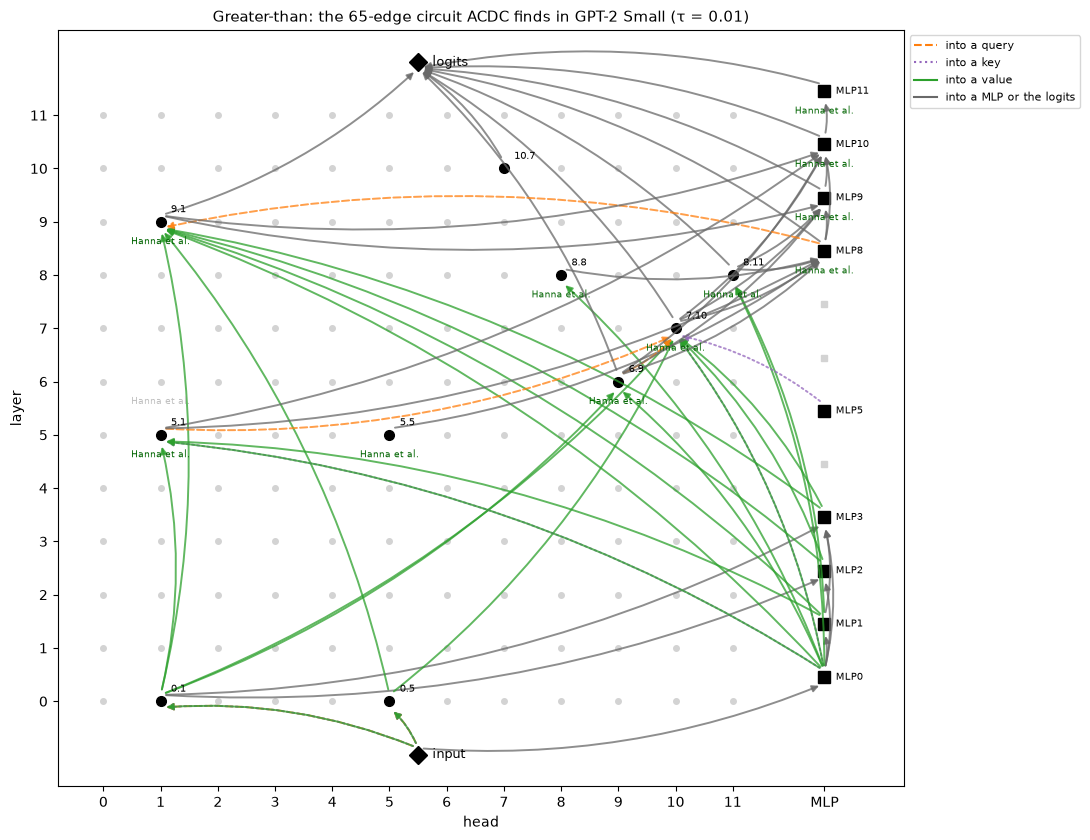

In [40]:
HANNA_HEADS = ["a5.1", "a5.5", "a6.1", "a6.9", "a7.10", "a8.8", "a8.11", "a9.1"]
HANNA_MLPS = ["m8", "m9", "m10", "m11"]
rows = [{"node": n, "Hanna et al.": "yes", "ACDC": "yes" if n in gt_nodes else "no"} for n in HANNA_HEADS + HANNA_MLPS]
rows += [{"node": n, "Hanna et al.": "no", "ACDC": "yes"} for n in gt_nodes if n not in HANNA_HEADS + HANNA_MLPS]
display(pd.DataFrame(rows).set_index("node"))

utils.draw_gpt2_circuit(
    gt_circuit, gpt2_graph.SENDER_NAMES, gpt2_graph.RECEIVER_NAMES,
    title=f"Greater-than: the {int(gt_circuit.sum())}-edge circuit ACDC finds in GPT-2 Small (τ = 0.01)",
    highlight={h: "Hanna et al." for h in HANNA_HEADS + HANNA_MLPS},
)

<details>
<summary>Help - how should I interpret this?</summary>

Seven of Hanna et al.'s eight heads are in ACDC's circuit (all but 6.1), and so are all four of their MLPs. The wiring matches their account. Almost all of the edges into the
mid-layer heads go into their **values** (green), mostly from MLP 0 and the other early MLPs: these heads attend to the start year and move what the early layers computed about it
to the final position. Their outputs go to MLPs 8-11 and the logits, which turn it into the comparison.

ACDC also keeps components that aren't on Hanna et al.'s list: heads 0.1, 0.5 and 10.7, and MLPs 0, 1, 2, 3 and 5. Most of them sit at the bottom of the graph, processing the year
token before the mover heads read it. MLP 0 in particular is often treated as part of the embedding in analyses of GPT-2, so leaving it off a node list is a convention rather than
a claim that it doesn't matter. The next cell shows how much that convention matters.

Head 6.1 is the one disagreement in the other direction: it's in Hanna et al.'s circuit, but ACDC removed its edges at $        au = 0.01$. Either its contribution on our prompts
is below the threshold, or another mover head makes it redundant. Checking its single-edge effects, or rerunning at a lower threshold, would tell you which.
</details>

## Faithfulness on held-out prompts

Finally, the same evaluation as in 3️⃣: faithfulness on held-out prompts with the task metric (here the probability difference from [8.2]: probability on years greater than the
start year minus probability on the others), against random circuits of the same size. We'll also evaluate Hanna et al.'s circuit, as the subgraph containing every edge between its
nodes (plus the input embedding and the logits). Their circuit is defined by nodes, so this contains many more edges than ACDC's. We evaluate it twice: with exactly the node list
above, and with MLP 0 added, for a reason that will become clear.

Probability difference: full model 0.838, empty circuit -0.559
  ACDC (65 edges)                        faithfulness 0.78
  Hanna et al. nodes (156 edges)         faithfulness 0.00
  Hanna et al. nodes + MLP0 (186 edges)  faithfulness 0.69
  random circuits (65 edges)             faithfulness median 0.00, max 0.00


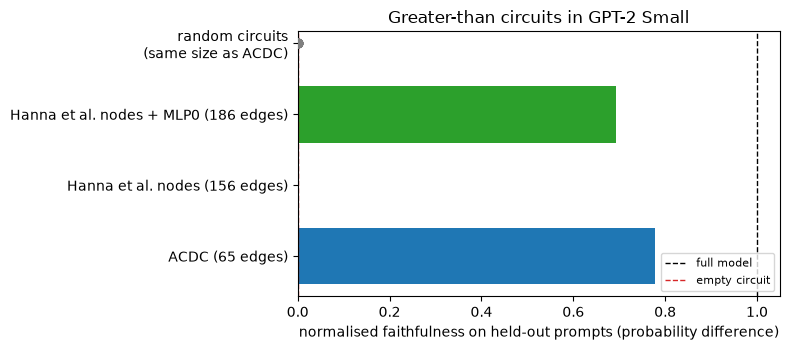

In [41]:
gt_heldout_corrupt_out = gpt2_graph.sender_activations(gpt2, gt_heldout.corrupt_tokens)


@t.inference_mode()
def gt_metric(circuit: Tensor) -> float:
    logits = utils.gpt2_circuit_logits(gpt2, gt_heldout.clean_tokens, gt_heldout_corrupt_out, circuit, GPT2_EDGES, gpt2_graph)
    return gt_heldout.metric(logits[:, None], gt_heldout.answers).mean().item()


GT_FULL, GT_EMPTY = gt_metric(GPT2_EDGES), gt_metric(t.zeros_like(GPT2_EDGES))


def node_circuit(nodes: list[str]) -> Tensor:
    """Every valid edge between the given nodes (plus the input embedding and the logits)."""
    keep = set(nodes) | {"input", "logits"}
    circuit = t.zeros_like(GPT2_EDGES)
    for u, v in GPT2_EDGES.nonzero().tolist():
        if gpt2_graph.SENDER_NAMES[u] in keep and gpt2_graph.RECEIVER_NAMES[v].split("<")[0] in keep:
            circuit[u, v] = True
    return circuit


hanna_circuit = node_circuit(HANNA_HEADS + HANNA_MLPS)
hanna_m0_circuit = node_circuit(HANNA_HEADS + HANNA_MLPS + ["m0"])

generator = t.Generator().manual_seed(4)
n_gt = int(gt_circuit.sum())
gt_random = [faithfulness(gt_metric(random_circuit(GPT2_EDGES, n_gt, generator)), GT_FULL, GT_EMPTY) for _ in range(20)]
gt_results = {
    f"ACDC ({n_gt} edges)": faithfulness(gt_metric(gt_circuit), GT_FULL, GT_EMPTY),
    f"Hanna et al. nodes ({int(hanna_circuit.sum())} edges)": faithfulness(gt_metric(hanna_circuit), GT_FULL, GT_EMPTY),
    f"Hanna et al. nodes + MLP0 ({int(hanna_m0_circuit.sum())} edges)": faithfulness(gt_metric(hanna_m0_circuit), GT_FULL, GT_EMPTY),
}
print(f"Probability difference: full model {GT_FULL:.3f}, empty circuit {GT_EMPTY:.3f}")
for name, f in gt_results.items():
    print(f"  {name:<38} faithfulness {f:.2f}")
print(f"  {'random circuits (' + str(n_gt) + ' edges)':<38} faithfulness median {np.median(gt_random):.2f}, max {max(gt_random):.2f}")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(list(gt_results), list(gt_results.values()), color=["tab:blue", "tab:orange", "tab:green"])
ax.scatter(gt_random, ["random circuits\n(same size as ACDC)"] * len(gt_random), color="gray", alpha=0.6, zorder=3)
ax.axvline(1, color="black", ls="--", lw=1, label="full model")
ax.axvline(0, color="tab:red", ls="--", lw=1, label="empty circuit")
ax.set_xlabel("normalised faithfulness on held-out prompts (probability difference)")
ax.set_title("Greater-than circuits in GPT-2 Small")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

<details>
<summary>Expected output</summary>

<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace">Probability difference: full model 0.838, empty circuit -0.559
  ACDC (65 edges)                        faithfulness 0.78
  Hanna et al. nodes (156 edges)         faithfulness 0.00
  Hanna et al. nodes + MLP0 (186 edges)  faithfulness 0.69
  random circuits (65 edges)             faithfulness median 0.00, max 0.00</pre>

</details>

<details>
<summary>Help - how should I interpret this?</summary>

ACDC's 65-edge circuit recovers 78% of the probability difference on held-out prompts. Random circuits of the same size recover nothing (all 20 of them score 0.00).

The surprise is Hanna et al.'s circuit. With exactly the node list above, it recovers **nothing** (0.00), despite having 156 edges and containing almost every component ACDC found
important. Add MLP 0 and it jumps to 0.69. The mover heads read the start year through their values, and the representation of the year token that they need is built largely by MLP
0. Without MLP 0 in the circuit, they read its *corrupted* output, which is information about "01", and the rest of the circuit compares the end year against the wrong start year.

That isn't evidence that Hanna et al.'s analysis is wrong. A node list written in a paper carries conventions, like "MLP 0 counts as part of the embedding", that are invisible
until you turn it into an edge mask and run it. It's a good reason to evaluate a circuit claim in exactly the form you're going to use it. And it's one of the things automated
methods are good for: ACDC has no conventions, so it kept MLP 0, and its circuit is more faithful with a third of the edges.
</details>

## Summary of 4️⃣

- Your ACDC implementation runs unchanged on GPT-2 Small. With $	au = 0.01$ it tests 3,203 of the 32,491 edges (the rest are dropped along with nodes that leave the circuit) and keeps 65, in a few minutes on a GPU.
- It recovers 7 of the 8 heads and all 4 MLPs of Hanna et al.'s hand-found greater-than circuit, wired the way their account predicts, plus the early MLPs that build the representation of the year.
- On held-out prompts, the 65-edge circuit recovers 78% of the behaviour, and random circuits of the same size recover nothing. Hanna et al.'s node list recovers nothing either until MLP 0 is added (0.69): circuit claims carry conventions that only show up when you evaluate them as edge masks.

# ☆ Bonus

## Does the order matter?

ACDC is greedy, so the order in which it tests edges can change the answer whenever two edges are redundant: whichever is tested first gets removed, and the other one is then
essential. Rerun ACDC on the two-layer model with senders tested earliest-first (drop the `reversed`), and with receivers in a random order that still respects the topology
(shuffle the heads within each layer). Measure the overlap between the circuits (e.g. the Jaccard index of their edge sets) and their faithfulness. Are the induction-circuit edges
stable? Which edges move?

## ACDC with the task metric

We used KL divergence as ACDC's metric and the task metric only for evaluation. Try the reverse: run ACDC with the negative induction log probability on the discovery prompts. A
signed task metric can *decrease* when an edge is cut, if that edge was hurting performance, and ACDC will happily remove it. How does the circuit change? How does its KL
divergence from the full model compare with the KL-based circuit's? The ACDC paper discusses this choice in its appendix.

## Thresholds that add up

At $\tau = 0.3$ the two-layer circuit has 16 edges and a KL divergence above 3, even though no single removal cost more than 0.3. Track the KL along the run (add a callback or a
list to `acdc`) and plot it against the number of edges tested. Where do the large jumps happen? Can you design a variant of ACDC that stops when the *total* KL exceeds a budget,
rather than thresholding each step?

## What does head 0.4 contribute?

We found that 0.4 attends mostly to the token two positions back, and that ACDC keeps its edges into both the queries and the keys of the induction heads. A natural hypothesis: it
lets the induction heads match a longer prefix (the token *and* the one before it), which should matter most when the current token occurs more than once in the first half. Build
prompts where that happens (repeat some tokens within the random sequence) and compare the induction log probability with and without 0.4's edges, using `run_graph`.

## Head-level graphs, and pre-filtering with attribution

ACDC's cost is set by the number of edges it tests. Two common ways to cut it: use a coarser graph (one receiver per head instead of three, which divides the number of head-input
edges by three), or use a cheap attribution method like EAP-IG from [8.2] to discard most edges before ACDC starts, and run ACDC only on the rest. Implement one of them on
greater-than, and compare the circuit and its faithfulness with the full run above. What do you lose?

## Further reading

- Conmy, Mavor-Parker, Lynch, Heimersheim & Garriga-Alonso (2023), [*Towards Automated Circuit Discovery for Mechanistic Interpretability*](https://arxiv.org/abs/2304.14997). The ACDC paper. Section 4 has the ROC evaluation against reference circuits for IOI, greater-than, docstring, induction and tracr models.
- Wang, Variengien, Conmy, Shlegeris & Steinhardt (2022), [*Interpretability in the Wild: a Circuit for Indirect Object Identification in GPT-2 small*](https://arxiv.org/abs/2211.00593). Introduces the faithfulness, completeness and minimality criteria.
- Hanna, Liu & Variengien (2023), [*How does GPT-2 compute greater-than?*](https://arxiv.org/abs/2305.00586). The hand-found greater-than circuit.
- Syed, Rager & Conmy (2023), [*Attribution Patching Outperforms Automated Circuit Discovery*](https://arxiv.org/abs/2310.10348). EAP, compared with ACDC on the same benchmarks.
- Bhaskar, Wettig, Friedman & Chen (2024), [*Finding Transformer Circuits with Edge Pruning*](https://arxiv.org/abs/2406.16778). Circuit discovery as a continuous optimisation over edge masks, which scales to much larger models.
- Miller, Chughtai & Saunders (2024), [*Transformer Circuit Faithfulness Metrics Are Not Robust*](https://arxiv.org/abs/2407.08734). How much faithfulness numbers depend on choices like the corruption and the ablation, which you saw in the try-it-yourself cell.
- Chan et al. (2022), [*Causal Scrubbing*](https://www.alignmentforum.org/posts/JvZhhzycHu2Yd57RN/causal-scrubbing-a-method-for-rigorously-testing). A stricter way of testing a circuit hypothesis, which is the subject of [8.5].